# The court case duration model: the whole pipeline in one notebook

**IDSE (CS3006) project.** This notebook takes real Indian court records from the raw download all
the way to the model you can try at [otlr.vercel.app/model](https://otlr.vercel.app/model). At every
step it says **what we did, why, and what we found**.

**Our question.** Court cases in India often take years. We wanted to know **which cases take long,
where, and whether we can tell on the day a case is filed.** The answer is meant for planning, for
example to estimate how many of this year's new cases will still be pending next year. It is not a
prediction for any one person's case.

**The short answer.** We can tell which *type* of case will be quick. But for real disputes, what we
know on the first day says very little about which ones will finish fast, and most of a dispute's
time is spent after its first hearing.

The notebook has two parts:

- **Part A, the data:** the question, where the data came from, what was wrong with it, how we
  cleaned it, two problems that would have fooled us, how we made the yes/no answers, and what the
  data shows.
- **Part B, the model:** what the model is allowed to see, how we split the years, the simple rules
  it must beat, the three models we tried, the one we chose, how well it does on cases it never saw,
  what it relies on, a few extra analyses, its limits, and two real cases run through it.

Every number here is calculated from the cleaned data (`data/clean/10/`) or read from the result
files our scripts wrote (`reports/*.json`). No number is typed in by hand. Slow steps (the random
forests, the shuffle test) are not run again; their results are read from the reports. All code is
the project's own package in `src/courtcases/`.

Data: Development Data Lab's judicial data (eCourts, cases filed 2010–2018), licence ODbL v1.0.

In [1]:
import json
import sys
import time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "scripts"))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter

from courtcases import plotstyle as ps

ps.apply()
CLEAN, KEYS = ROOT / "data/clean/10", ROOT / "data/raw/ddl/keys"
REPORTS, ARTIFACT = ROOT / "reports", ROOT / "artifacts/within_1y"
A = json.loads((REPORTS / "analysis.json").read_text())            # scripts/analyse.py
R = json.loads((REPORTS / "within_1y_results.json").read_text())   # scripts/train_within_1y.py
E = json.loads((REPORTS / "experiments.json").read_text())         # scripts/experiments.py
D = json.loads((REPORTS / "days_regression.json").read_text())     # scripts/regress_days.py
H = json.loads((REPORTS / "difficulty.json").read_text())          # scripts/analyse_difficulty.py
META = json.loads((ARTIFACT / "metadata.json").read_text())
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.width", 120)

CHECKS = []


def check(what, here, reported, tol=5e-4):
    '''Compare a number computed in this notebook with the one in the reports.'''
    ok = abs(float(here) - float(reported)) <= tol
    CHECKS.append((what, ok))
    print(f"  [{'agrees' if ok else 'DISAGREES'}] {what}: notebook {here:,.4f}, report {reported:,.4f}")


def key(name):
    return pd.read_csv(KEYS / name, dtype=str, keep_default_na=False)


print("ready:", ROOT)

ready: /Users/yashvanths/Study/IDSE/idse-game/pipeline


# Part A · The data analysis pipeline

## A1 · The question

**Why this question.** Courts need to plan: how many judges and staff they need, and which cases
legal-aid offices should try to settle. For that they need to know which kinds of case take long,
and where.

**What we ask.** One clear question the model can answer:

> If we only know what is written on the day a case is filed in a Tamil Nadu district court, how
> likely is it to **finish within one year**?

"Finish" means the case ended *in that court*: a judgment, a dismissal, a settlement, a Lok Adalat,
or the file closed because the accused ran away. If the case was sent to another court, it has
**not** finished; it is still going on somewhere else.

**Why yes/no and not "how many days".** Many cases had not finished when the data was collected, so
we do not know their total number of days. But we can answer "did it finish within a year?" for
every case we could watch for at least a year (step A7 shows how).

In [2]:
nat, tn = A["national"], A["tamil_nadu"]
print("Question:", META["question"])
print(f"Cases in the download (all India, filings 2010-2018): {nat['cases']:,}")
print(f"Cases in Tamil Nadu, the state we model:                {tn['cases']:,}")
print(f"\nTakeaway: one clear question, answered with {tn['cases']:,} real Tamil Nadu cases "
      f"out of {nat['cases'] / 1e6:.1f} million across India.")

Question: Disposed of within 365 days of filing (Tamil Nadu district courts)
Cases in the download (all India, filings 2010-2018): 80,935,944
Cases in Tamil Nadu, the state we model:                3,640,055

Takeaway: one clear question, answered with 3,640,055 real Tamil Nadu cases out of 80.9 million across India.


## A2 · The data and where it came from

**What.** Development Data Lab (DDL), a research group, collected the records from the government's
eCourts website, removed people's names, and published one row per case for every district court in
India, for cases filed from 2010 to 2018. The data comes as one big folder: one file of cases per
year (16 GB in total), one file with the law and section of each case, and small "key" files that
turn number codes (such as the case type) into words.

**How we got it.** The folder can only be downloaded all at once, as one very large stream. Our script
`scripts/fetch_ddl.py` reads the stream as it arrives, keeps only the files we need, checks that each
file arrived without errors, and stops early. Then `scripts/build_dataset.py` turns the files into a
smaller, faster format (Parquet). It reads **every column as text**, because a code like "01" would
become 1 as a number and then no longer match the key files.

**Licence.** The licence file in the download is ODbL v1.0, which lets us use the data as long as we
credit it.

Below: three raw rows exactly as they are stored, and how many cases there are each year.

624,243 Tamil Nadu cases filed in 2017, 19 columns, all stored as text


,case 297999,case 294782,case 396642
ddl_case_id,10-14-14-207305007302017,10-14-12-203602001002017,10-18-21-230402002242016
year,2017,2017,2017
state_code,10,10,10
dist_code,14,14,18
court_no,14,12,21
cino,TNVR0B0014972017,TNVR090002032017,TNCB120010562016
judge_position,judicial magistrate court,sub court,judicial magistrate court
female_defendant,0 male,-9998 unclear,0 male
female_petitioner,-9998 unclear,1 female,-9998 unclear
female_adv_def,-9999,-9999,-9999


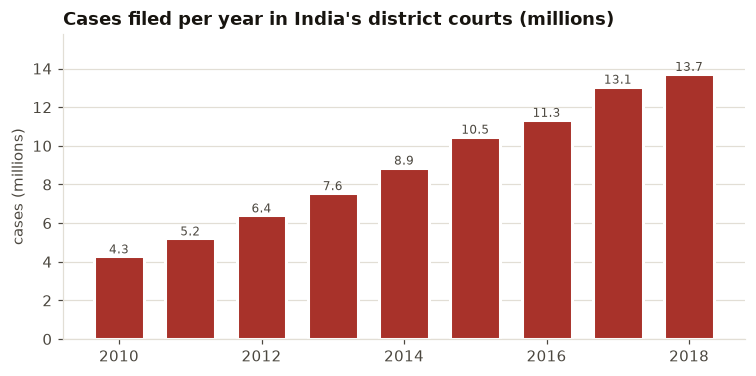

Takeaway: 80,935,944 cases, 2010-2018; codes, dates and genders all come as text and have to be turned into readable values.


In [3]:
raw = pd.read_parquet(CLEAN / "cases_2017.parquet")   # Tamil Nadu, filed in 2017, every column as text
print(f"{len(raw):,} Tamil Nadu cases filed in 2017, {raw.shape[1]} columns, all stored as text")
display(raw.sample(3, random_state=1).T.rename(columns=lambda c: f"case {c}"))

per_year = pd.Series(nat["cases_per_year"]).rename(int)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(per_year.index, per_year.values / 1e6, color=ps.SERIES[0], width=0.7,
       edgecolor=ps.SURFACE, linewidth=2)
for x, v in per_year.items():
    ax.text(x, v / 1e6 + 0.15, f"{v / 1e6:.1f}", ha="center", fontsize=8, color=ps.INK_2)
ax.set_title("Cases filed per year in India's district courts (millions)")
ax.set_ylabel("cases (millions)")
ax.grid(axis="x", visible=False)
ax.set_ylim(0, per_year.max() / 1e6 * 1.15)
plt.show()

print(f"Takeaway: {nat['cases']:,} cases, {per_year.index.min()}-{per_year.index.max()}; "
      f"codes, dates and genders all come as text and have to be turned into readable values.")

**The data, column by column.** Each row is **one court case**. The table below lists every
column, what it means, how much of it is missing (for Tamil Nadu cases filed 2015–2017), and what we
do with it. The law and section come from the second file, matched by case id. **What the data does
not have:** names (removed), the full list of hearing dates (only the first, last and next), and
anything after early 2019, when it was collected.

In [4]:
card = pd.DataFrame(H["dataset_card"])[["column", "meaning", "use", "blank_share", "sentinel_share"]]
card.columns = ["column", "what it is", "how we use it", "blank", "coded unknown"]
print(f"{len(card)} columns, one row per case")
card.style.format({"blank": "{:.1%}", "coded unknown": "{:.1%}"}).hide(axis="index")

19 columns, one row per case


column,what it is,how we use it,blank,coded unknown
ddl_case_id,Anonymous case id,joins cases to their law and section,0.0%,0.0%
year,Filing year,splitting into train and test,0.0%,0.0%
state_code,State,filter to Tamil Nadu,0.0%,0.0%
dist_code,District,model input,0.0%,0.0%
court_no,Court within the district,cleaning only; a visitor can't know it,0.0%,0.0%
cino,eCourts case number,not used,0.0%,0.0%
judge_position,Type of judge / court (free text),"model input, after cleaning",0.0%,0.0%
female_defendant,"Defendant's gender, inferred from name","description only, kept out of the model",0.0%,23.6%
female_petitioner,"Petitioner's gender, inferred from name","description only, kept out of the model",0.0%,48.4%
female_adv_def,Defendant advocate's gender,not used,0.0%,85.8%


## A3 · The raw mess, before cleaning

**What.** Before fixing anything, we measured what was wrong. Five problems, each shown below with
real values from the data:

1. **Missing values are hidden** as blanks and as special codes: `-9998` means "unclear" and `-9999`
   means "missing".
2. **Impossible dates**: decisions in the year 0001 or 7201, the fake date `5000-01-01`, and cases
   "decided" before they were filed.
3. **One law, thousands of spellings.** Court staff type the law names by hand: 29,857 different
   spellings for a few dozen laws.
4. **Court names are typed by hand too**, with spelling mistakes ("trail", "musif", "subardinate").
5. **Section numbers are free text**: "138r/w142", "OVIIR1".

**Why measure first.** A wrong fix is worse than an honest "unknown", so every cleaning rule in the
next step reports how many rows it changed.

In [5]:
# 1. blanks and sentinels, as a share of the raw 2017 rows
def missing(col):
    s = raw[col]
    return pd.Series({"blank": (s == "").mean(),
                      "-9998 (unclear)": s.str.startswith("-9998").mean(),
                      "-9999 (missing)": s.str.startswith("-9999").mean()})


miss = pd.DataFrame({c: missing(c) for c in raw.columns}).T
print("Columns with blanks or sentinel codes (share of 2017 Tamil Nadu rows):")
display(miss[(miss > 0).any(axis=1)].style.format("{:.1%}"))

# 2. impossible dates: the raw year typed, per date column
dates = ["date_of_decision", "date_first_list", "date_last_list", "date_next_list"]
typed = pd.DataFrame({c: {"earliest year typed": pd.to_numeric(raw[c].str[:4], errors="coerce").min(),
                          "latest year typed": pd.to_numeric(raw[c].str[:4], errors="coerce").max()}
                      for c in dates}).T.astype("Int64")
display(typed)

# 3. one law, many spellings (act_key.csv lists every raw law name in the country with its count)
acts_key = key("act_key.csv")
acts_key["count"] = pd.to_numeric(acts_key["count"])
ni = acts_key[acts_key["act_s"].str.contains(r"negotiab|n\.? ?i\.? ?act", case=False, regex=True)]
print(f"\n{len(acts_key):,} distinct raw law names in the country. "
      f"{len(ni):,} of them are spellings of the Negotiable Instruments Act, for example:")
display(ni.nlargest(10, "count")[["act_s", "count"]].rename(columns={"act_s": "raw law name"}))

# 4. court names and 5. section strings
courts = raw["judge_position"]
odd = courts[courts.str.contains("trail|musif|subardinate|mgistrate|magistarte")].unique()
print(f"{courts.nunique()} distinct court names in 2017 alone; with typos such as:", list(odd[:4]))
section_key = key("section_key.csv")
ni_sections = section_key[section_key["section_s"].str.contains(r"^138", regex=True)]["section_s"]
print(f"{len(ni_sections):,} distinct ways of writing section 138 (cheque bounce), e.g.",
      list(ni_sections.sample(6, random_state=3)))
print("\nTakeaway: before we can count anything, the law names, court names, sections, dates and "
      "special codes must be cleaned; every cleaning rule is tested on these real values.")

Columns with blanks or sentinel codes (share of 2017 Tamil Nadu rows):


,blank,-9998 (unclear),-9999 (missing)
female_defendant,0.0%,19.1%,4.2%
female_petitioner,0.0%,48.6%,3.8%
female_adv_def,0.0%,1.7%,86.1%
female_adv_pet,0.0%,9.5%,45.0%
purpose_name,7.1%,0.0%,0.0%
date_of_decision,34.1%,0.0%,0.0%
date_first_list,7.0%,0.0%,0.0%
date_last_list,0.0%,0.0%,0.0%
date_next_list,6.5%,0.0%,0.0%


,earliest year typed,latest year typed
date_of_decision,2014,2071
date_first_list,2011,3027
date_last_list,2011,5000
date_next_list,2014,3029



29,857 distinct raw law names in the country. 217 of them are spellings of the Negotiable Instruments Act, for example:


,raw law name,count
11007,Negotiable Instruments Act,1740873.0
10809,"NEGOTIABLE INSTRUMENTS ACT, 1881",790884.0
10808,NEGOTIABLE INSTRUMENTS ACT,780690.0
11001,Negotiable Instrument Act,358348.0
11009,Negotiable Instruments Act \,281877.0
11012,Negotiable Instruments Act 1881,240837.0
11023,NegotiableInstrumentsAct,104925.0
10734,N. I. Act,71406.0
11014,Negotiable Instruments Act \,63929.0
19894,U/S 138 of N.I Act,56916.0


102 distinct court names in 2017 alone; with typos such as: ['principal district musif court complex, thoothukud', 'special court for the exclusive trail of ec act cases', 'district musif court, virudhunagar', 'spl magistarte for land grabbing cases']


11,790 distinct ways of writing section 138 (cheque bounce), e.g. ['138/4201PC', '138,142OFNIACTR/W.190-1AOFCr.P.C.', '138,200ofcrpc', '138N.iact', '138AND142OFN.IACTR/W190aOFCRIMINALACT', '138Rule']

Takeaway: before we can count anything, the law names, court names, sections, dates and special codes must be cleaned; every cleaning rule is tested on these real values.


## A4 · Cleaning, with before and after counts

**What.** Each problem gets one small function in `src/courtcases/`, and every function has tests
(142 tests in total, run with `uv run pytest`):

- **Law names:** make them lower-case, keep only the letters, then match them against a list of
  patterns, from the most specific to the most general. A name that matches nothing stays "Other";
  we do not guess.
- **Section numbers:** keep the main section: "304(B)" → 304B, "138r/w142" → 138, "OVIIR1" → Order 7.
- **Court names:** matched to 15 court types; "Other / unclear" if nothing matches.
- **Dates:** any date outside 1950–2022 is removed and counted; cases "decided before filing" are
  marked.
- **Special codes:** `-9998` → "unclear", `-9999` → "missing".
- **How a case ended (52 codes):** each code is put in one group: decided, settled, dismissed,
  disposed, dormant, **moved** (sent to another court: it left, it did not end), interim (bail
  orders) or missing.

**Why these choices.** We never "fix" a wrong date (we cannot know what it should have been) and we
never guess a law; we count what we could not fix. A **moved** case is not counted as finished,
because counting transfers as endings would make courts look faster than they are.

The code below runs the real functions and prints how much each one changed.

  [agrees] share of law rows mapped to a named law: notebook 0.9407, report 0.9407


,before,after
field,,
law names (all India),"29,857 raw strings","54 laws; 94.1% of rows named, 2.0% junk ('.', '---', 'AC..."
court names (Tamil Nadu),116 raw strings,15 court levels (incl. unclear)
decision dates,years 0001 to 9201 typed,"66 blanked as impossible; 23,497 decided before filing, ..."
last-hearing dates,5000-01-01 placeholders,"95,219 blanked"
gender,-9998 / -9999 codes,"defendant unclear 22%, petitioner unclear 45%; kept out ..."
dispositions,52 categories,7 groups


Section strings, distinct values before and after:


,raw strings,after primary_section()
Indian Penal Code,493,492
Negotiable Instruments Act,2454,227
Motor Vehicles Act,24310,616
Code of Civil Procedure,61776,1134


Outcome groups (share of all Tamil Nadu cases):


,share
group,
decided,33.2%
missing,26.4%
dismissed,19.0%
moved,13.9%
disposed,5.0%
settled,2.6%
interim,0.0%


  [agrees] share of cases in the 'moved' group: notebook 0.1393, report 0.1393


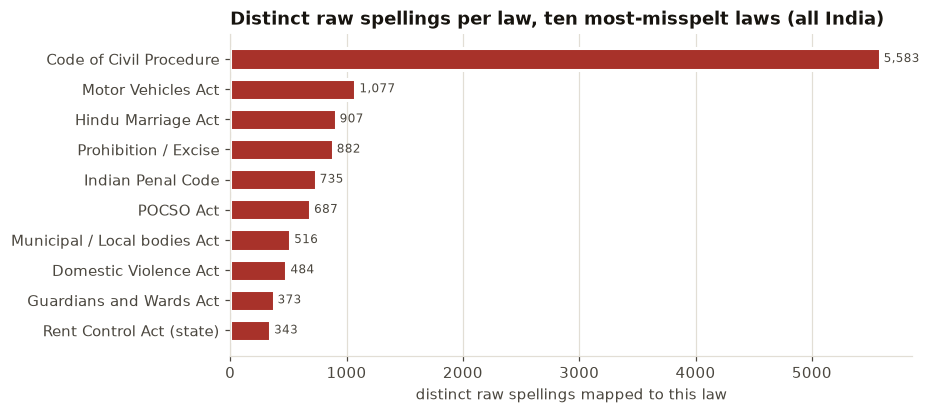

Takeaway: 29,857 law spellings became 54 laws (94.1% of rows named), 116 court names became 15 court types, 23,497 impossible cases were set aside, and 14% of cases were 'moved' to another court, not finished.


In [6]:
from courtcases.acts import UNKNOWN, canonical_act
from courtcases.courts import court_level
from courtcases.outcomes import outcome_group
from courtcases.sections import primary_section

lab = pd.read_parquet(CLEAN / "labelled.parquet")   # every Tamil Nadu case, decoded (scripts/label_cases.py)

# laws: 29,857 raw names -> a few dozen laws, weighted by how many case rows use each name
acts_key["law"] = acts_key["act_s"].map(canonical_act)
named = ~acts_key["law"].isin([UNKNOWN, "Other"])
rows = acts_key["count"].sum()
def share(m):
    return acts_key.loc[m, "count"].sum() / rows


law_named, law_junk, law_other = share(named), share(acts_key.law == UNKNOWN), share(acts_key.law == "Other")
check("share of law rows mapped to a named law", law_named, tn["cleaning"]["law_rows_named"])

# sections: distinct strings before and after, for four big laws
acts = pd.read_parquet(CLEAN / "acts_sections.parquet", columns=["act", "section"])
acts["law"] = acts["act"].map(acts_key.set_index("act")["act_s"]).fillna("").map(canonical_act)
raw_sec = acts["section"].map(section_key.set_index("section")["section_s"]).fillna("")
sections_table = pd.DataFrame({
    law: {"raw strings": raw_sec[acts.law == law].nunique(),
          "after primary_section()": raw_sec[acts.law == law].map(primary_section).nunique()}
    for law in ["Indian Penal Code", "Negotiable Instruments Act", "Motor Vehicles Act",
                "Code of Civil Procedure"]}).T

# courts, dates, sentinels, outcomes
lab["court_level"] = lab["judge_position"].map(court_level)
lab["group"] = lab["disp"].map(outcome_group)
before_after = pd.DataFrame([
    ["law names (all India)", f"{len(acts_key):,} raw strings",
     (f"{acts_key.loc[named, 'law'].nunique()} laws; {law_named:.1%} of rows named, "
      f"{law_junk:.1%} junk ('.', '---', 'ACT'), {law_other:.1%} left as Other")],
    ["court names (Tamil Nadu)", f"{lab['judge_position'].nunique()} raw strings",
     f"{lab['court_level'].nunique()} court levels (incl. unclear)"],
    ["decision dates", "years 0001 to 9201 typed",
     (f"{int(lab['date_of_decision_impossible'].sum()):,} blanked as impossible; "
      f"{int(lab['decided_before_filing'].sum()):,} decided before filing, set aside")],
    ["last-hearing dates", "5000-01-01 placeholders",
     f"{int(lab['date_last_list_impossible'].sum()):,} blanked"],
    ["gender", "-9998 / -9999 codes",
     (f"defendant unclear {(lab['defendant'] == 'unclear').mean():.0%}, "
      f"petitioner unclear {(lab['petitioner'] == 'unclear').mean():.0%}; kept out of the model")],
    ["dispositions", "52 categories", f"{lab['group'].nunique()} groups"],
], columns=["field", "before", "after"]).set_index("field")
display(before_after)
print("Section strings, distinct values before and after:")
display(sections_table)
groups = lab["group"].value_counts(normalize=True)
print("Outcome groups (share of all Tamil Nadu cases):")
display(groups.rename("share").to_frame().style.format("{:.1%}"))
check("share of cases in the 'moved' group", groups["moved"], tn["cleaning"]["outcome_groups"]["moved"])

fig, ax = plt.subplots(figsize=(8, 3.8))
spellings = acts_key[named].groupby("law").size().nlargest(10)
ps.hbar(ax, [s.replace(" (state liquor laws)", "") for s in spellings.index],
        list(spellings.values), fmt="{:,}")
ax.set_title("Distinct raw spellings per law, ten most-misspelt laws (all India)")
ax.set_xlabel("distinct raw spellings mapped to this law")
plt.show()

print(f"Takeaway: {len(acts_key):,} law spellings became {acts_key.loc[named, 'law'].nunique()} laws "
      f"({law_named:.1%} of rows named), {lab['judge_position'].nunique()} court names became "
      f"{lab['court_level'].nunique()} court types, {int(lab['decided_before_filing'].sum()):,} impossible "
      f"cases were set aside, and {groups['moved']:.0%} of cases were 'moved' to another court, not finished.")

## A5 · When was the data collected?

**What.** The data does not say when it was collected, but we need that date: if a case has no
decision, we only know it was *still pending on that day*. There is a clue. The number of decisions
recorded each month is steady for years, then suddenly drops. That drop is when the data was
collected.

**How.** Our function `cutoff.cliff` looks for the **first lasting drop**: the first month where that
month and the next two are all below half of a normal month (a normal month is the middle value of
the twelve months before it). We use "half" because the collection happened *during* February 2019,
and a half-collected month would make decided cases look pending. We do this **for each district**,
and use the state's date when a small district's numbers are too uneven to tell.

**A mistake we fixed.** Our first version used "the last normal-looking month" and put Tamil Nadu's
date in July 2020, which was wrong: after the collection a few courts kept adding records, and that
small trickle started to look "normal". We changed the rule and added a test so the mistake cannot
come back.

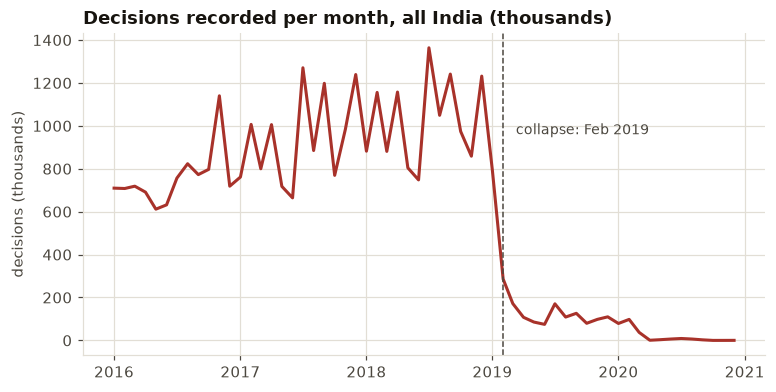

A normal month in 2018: 1,011,514 decisions; January 2019: 790,239; February: 286,163; March: 171,585.



Tamil Nadu as a whole: last reliable day = 2019-01-31
Per district: {datetime.date(2018, 12, 31): 5, datetime.date(2019, 1, 31): 26, datetime.date(2019, 2, 28): 2}
Matches data/clean/10/cutoffs.parquet used for the labels: True

Takeaway: the data was collected in January-February 2019; each district's last complete month is between 2018-12-31 and 2019-02-28.


In [7]:
from courtcases.cutoff import cliff, cutoffs, with_fallback

monthly = pd.Series(nat["monthly_decisions"])
monthly.index = pd.PeriodIndex(monthly.index, freq="M").to_timestamp()
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(monthly.index, monthly.values / 1e3, color=ps.SERIES[0])
normal = monthly.loc["2018"].median()
ax.axvline(pd.Timestamp("2019-02-01"), color=ps.INK_2, lw=1, ls="--")
ax.annotate("collapse: Feb 2019", (pd.Timestamp("2019-03-10"), normal / 1e3 * 0.95), fontsize=9,
            color=ps.INK_2)
ax.set_title("Decisions recorded per month, all India (thousands)")
ax.set_ylabel("decisions (thousands)")
plt.show()
print(f"A normal month in 2018: {normal:,.0f} decisions; January 2019: {monthly.loc['2019-01'].iloc[0]:,.0f}; "
      f"February: {monthly.loc['2019-02'].iloc[0]:,.0f}; March: {monthly.loc['2019-03'].iloc[0]:,.0f}.")

# the same rule, run live on Tamil Nadu's decision dates (all filing years together)
state_cutoff = cliff(lab["date_of_decision"], share=0.5)
district_cutoffs = cutoffs(lab, by=["state_code", "dist_code"], share=0.5)
district_cutoffs = with_fallback(district_cutoffs, cutoffs(lab, by="state_code", share=0.5),
                                 parent_of=lambda k: k[0])
saved = pd.read_parquet(CLEAN / "cutoffs.parquet")
print(f"\nTamil Nadu as a whole: last reliable day = {state_cutoff.date()}")
print("Per district:", district_cutoffs.dt.date.value_counts().sort_index().to_dict())
same = (district_cutoffs.reset_index(drop=True) == saved["cutoff"]).all()
print(f"Matches data/clean/10/cutoffs.parquet used for the labels: {same}")
print(f"\nTakeaway: the data was collected in January-February 2019; each district's last complete "
      f"month is between {district_cutoffs.min().date()} and {district_cutoffs.max().date()}.")

## A6 · The early years are incomplete

**What.** Take only the Tamil Nadu courts that already existed in 2010 and count their cases by
filing year. The same courts have 3.6 times more cases filed in 2018 than in 2010, and the share of
cases decided *on the same day they were filed* grows from under 1% to 18%.

**Why this matters.** Courts did not get 3.6 times busier. When a court started using computers, its
pending cases were entered, but most cases that had already finished quickly were not. So the early
years are missing their quick cases and look much slower than they really were. (This is called
*survivorship bias*: only the long cases "survived" into the records.) **So the model only uses cases
filed from 2015 to 2017.**

  [agrees] cases filed in 2018 in the courts present since 2010: notebook 622,473.0000, report 622,473.0000


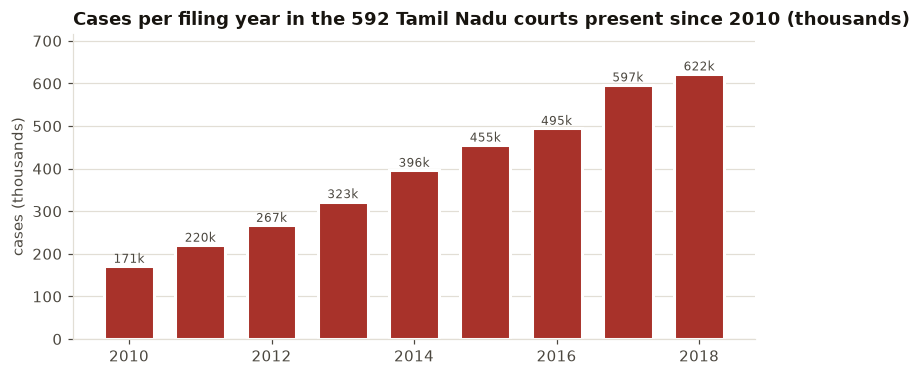

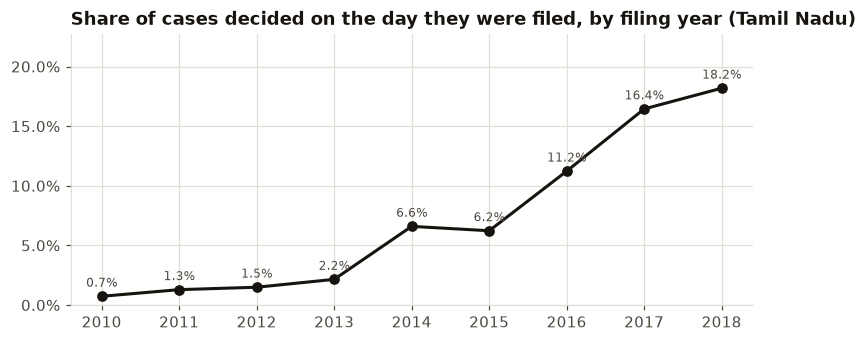

Takeaway: the same 592 courts record 170,958 cases filed in 2010 and 622,473 filed in 2018 (x3.6); cases decided on the day they were filed rise from 0.7% to 18.2%. The quick early cases were never entered, so the model only uses cases filed 2015-2017.


In [8]:
lab["court"] = lab["dist_code"] + "-" + lab["court_no"]
first_year = lab.groupby("court")["filing_year"].min()
old_courts = first_year[first_year == 2010].index
in_old = lab[lab["court"].isin(old_courts)].groupby("filing_year").size()
same_day = lab.groupby("filing_year")["observed_days"].apply(lambda s: (s == 0).mean())
check("cases filed in 2018 in the courts present since 2010", in_old[2018],
      tn["survivorship"]["cases_in_those_courts"]["2018"], tol=0.5)

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(in_old.index, in_old.values / 1e3, color=ps.SERIES[0], width=0.7, edgecolor=ps.SURFACE, linewidth=2)
for x, v in in_old.items():
    ax.text(x, v / 1e3 + 8, f"{v / 1e3:.0f}k", ha="center", fontsize=8, color=ps.INK_2)
ax.set_title(f"Cases per filing year in the {len(old_courts)} Tamil Nadu courts present since 2010 (thousands)")
ax.set_ylabel("cases (thousands)")
ax.grid(axis="x", visible=False)
ax.set_ylim(0, in_old.max() / 1e3 * 1.15)
plt.show()

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(same_day.index, same_day.values, marker="o", color=ps.SERIES[1])
for x, v in same_day.items():
    ax.text(x, v + 0.008, f"{v:.1%}", ha="center", fontsize=8, color=ps.INK_2)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_title("Share of cases decided on the day they were filed, by filing year (Tamil Nadu)")
ax.set_ylim(0, same_day.max() * 1.25)
plt.show()

print(f"Takeaway: the same {len(old_courts)} courts record {in_old[2010]:,} cases filed in 2010 and "
      f"{in_old[2018]:,} filed in 2018 (x{in_old[2018] / in_old[2010]:.1f}); cases decided on the day they were filed rise from "
      f"{same_day[2010]:.1%} to {same_day[2018]:.1%}. The quick early cases were never entered, so "
      f"the model only uses cases filed 2015-2017.")

## A7 · Labelling "finished within a year" without guessing

**What.** For every case, our function `target.label` records two things: how many days we could
watch it (until it ended, until it was sent to another court, or until the data was collected), and
whether it finished in this court during that time. If a case was still pending when the data was
collected, we only know it lasted *at least* that long.

Then each case gets an answer to "finished within 365 days?": **1** (yes), **0** (still pending after
365 days) or **unknown**. We only give an answer to cases filed **at least one year before the data
was collected**, so that every labelled case had a full year to finish. A case sent to another court
before day 365 stays unknown.

**Why this rule.** Our first version labelled every case it could. For cases filed in 2018, the quick
ones had already finished and were labelled "yes", while the slow ones were still pending and could
not be labelled at all. So 2018 came out more than 90% "within a year", which is clearly wrong. The
code below shows that mistake and then the correct labels.

Cases set aside as unusable, with the reason:


,cases
unusable,
decided before filing,23497
bail or interim order,1554
impossible decision date,41


,naive label: share 'within a year',honest label: share 'within a year',honest label: cases labelled
filing_year,,,
2014,36.0%,36.0%,"372,494"
2015,35.9%,35.9%,"405,062"
2016,43.5%,43.5%,"445,639"
2017,49.5%,49.5%,"549,273"
2018,92.8%,48.0%,"38,504"


Recomputed label identical to the saved within_1y column: True
  [agrees] share within a year, 2015 filings: notebook 0.3585, report 0.3585
  [agrees] share within a year, 2016 filings: notebook 0.4346, report 0.4346
  [agrees] share within a year, 2017 filings: notebook 0.4948, report 0.4948


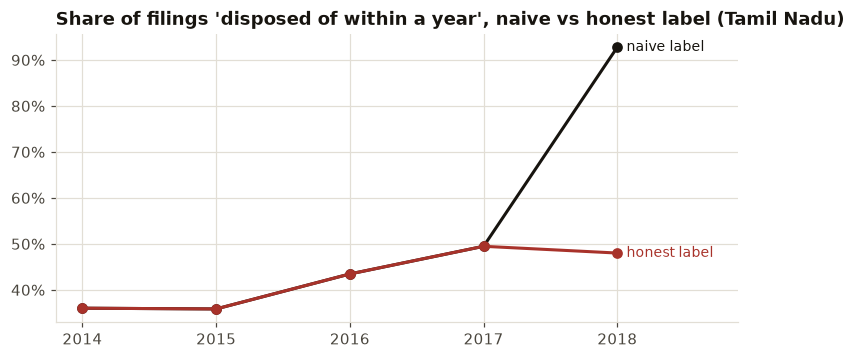

Takeaway: the wrong labels say 92.8% of 2018 cases finished within a year; when every case must have a full year, it is 48.0%. 1,399,974 cases filed 2015-2017 get a correct label (44% within a year).


In [9]:
from courtcases.target import within

usable = lab[lab["unusable"] == ""]
print("Cases set aside as unusable, with the reason:")
display(lab["unusable"].value_counts().drop("", errors="ignore").rename("cases").to_frame())

# the trap: label every case whose answer is "known" so far, with no eligibility rule
fast = usable["ended"] & (usable["observed_days"] <= 365)
slow = usable["observed_days"] > 365
naive = pd.Series(np.where(fast, 1.0, np.where(slow, 0.0, np.nan)), index=usable.index)
honest = within(lab, 365)
by_year = pd.DataFrame({
    "naive label: share 'within a year'": naive.groupby(usable["filing_year"]).mean(),
    "honest label: share 'within a year'": honest.groupby(lab["filing_year"]).mean(),
    "honest label: cases labelled": honest.groupby(lab["filing_year"]).count(),
}).loc[2014:2018]
display(by_year.style.format({"naive label: share 'within a year'": "{:.1%}",
                              "honest label: share 'within a year'": "{:.1%}",
                              "honest label: cases labelled": "{:,.0f}"}))
same_as_saved = honest.equals(lab["within_1y"]) or (honest.fillna(-1) == lab["within_1y"].fillna(-1)).all()
print(f"Recomputed label identical to the saved within_1y column: {same_as_saved}")
for y in (2015, 2016, 2017):
    check(f"share within a year, {y} filings", honest[lab.filing_year == y].mean(), tn["within_1y_by_year"][str(y)])

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(by_year.index, by_year.iloc[:, 0], marker="o", color=ps.SERIES[1], label="naive label")
ax.plot(by_year.index, by_year.iloc[:, 1], marker="o", color=ps.SERIES[0], label="honest label (full year of follow-up)")
ax.annotate("naive label", (2018, by_year.iloc[-1, 0]), xytext=(6, 0), textcoords="offset points", va="center", fontsize=9, color=ps.SERIES[1])
ax.annotate("honest label", (2018, by_year.iloc[-1, 1]), xytext=(6, 0), textcoords="offset points", va="center", fontsize=9, color=ps.SERIES[0])
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xticks(by_year.index)
ax.set_xlim(2013.8, 2018.9)
ax.set_title("Share of filings 'disposed of within a year', naive vs honest label (Tamil Nadu)")
plt.show()

elig = honest.notna() & lab["filing_year"].between(2015, 2017)
print(f"Takeaway: the wrong labels say {by_year.iloc[-1, 0]:.1%} of 2018 cases finished within a year; "
      f"when every case must have a full year, it is {by_year.iloc[-1, 1]:.1%}. {int(elig.sum()):,} cases filed "
      f"2015-2017 get a correct label ({honest[elig].mean():.0%} within a year).")

## A8 · What the cleaned data shows

**What.** Four views of the labelled Tamil Nadu data.

1. **"Typical days among finished cases" is misleading.** It drops to a few days for recent years
   only because the slow recent cases have not finished yet. The **Kaplan–Meier** method fixes this:
   it counts every case for as long as we watched it (a pending case counts as "still going" until
   the data was collected), so it is not fooled.
2. **By type of case:** bail-type petitions and petty-offence cases end within days; civil suits,
   criminal trials and accident claims take years.
3. **By court and by district:** the share finishing within a year goes from 8% to 54% between types
   of court, and from 19% to 74% between districts.
4. **By state (all of India):** the share of 2010 cases still pending nine years later goes from under
   2% to over 60%. Part of this is real backlog, and part is records that were never updated.

  [agrees] median days among decided, 2010 filings: notebook 1,366.0000, report 1,366.0000


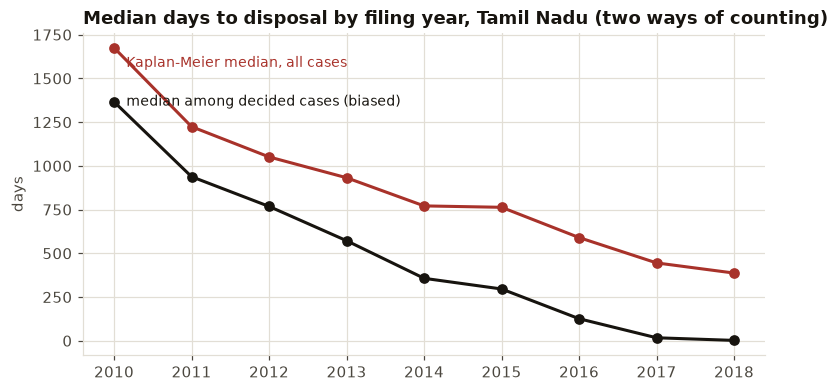

  [agrees] within a year, calendar cases (cc): notebook 0.2174, report 0.2174


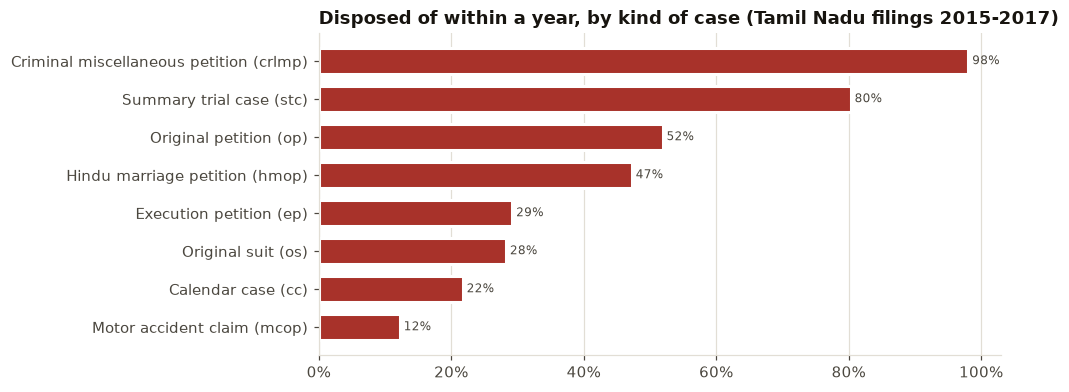

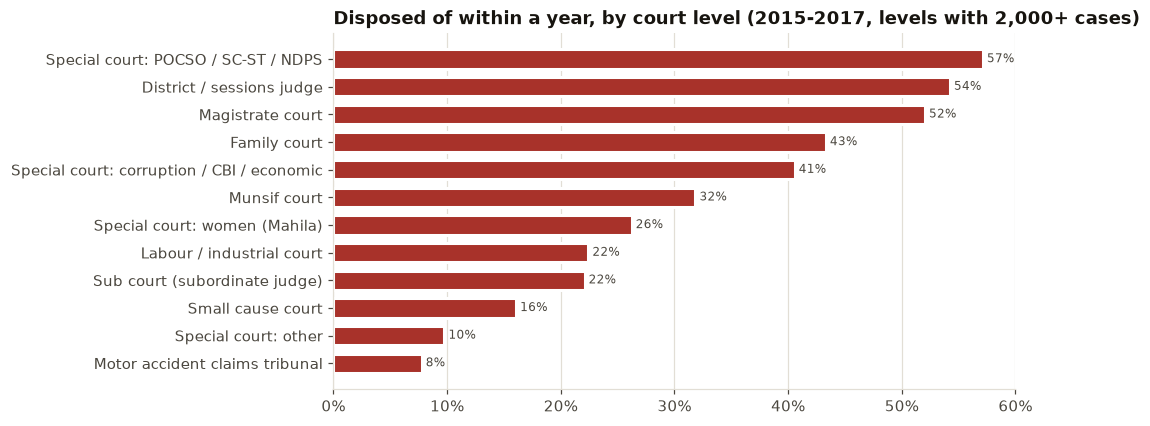

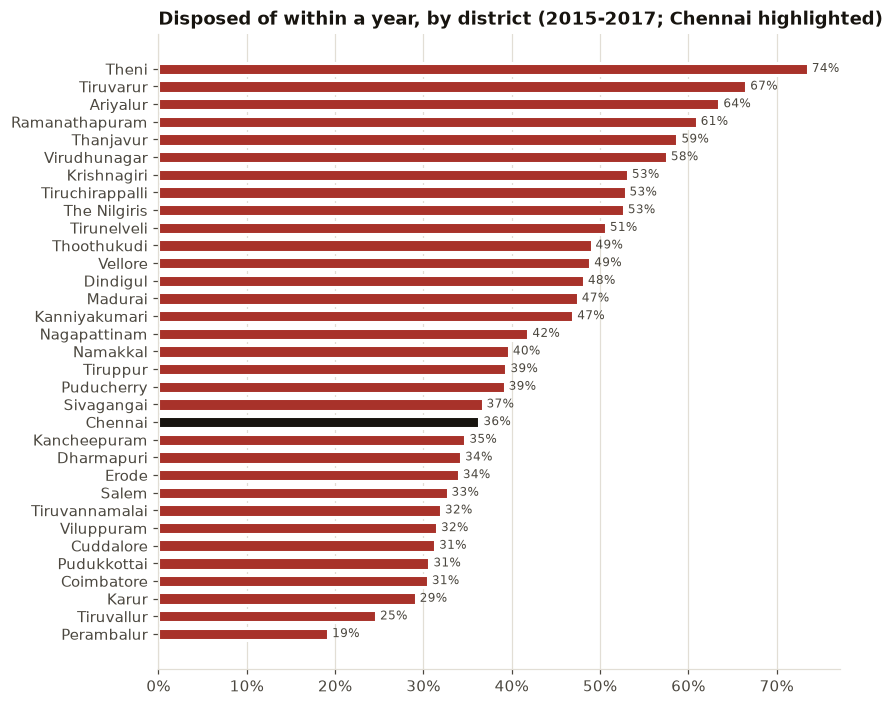

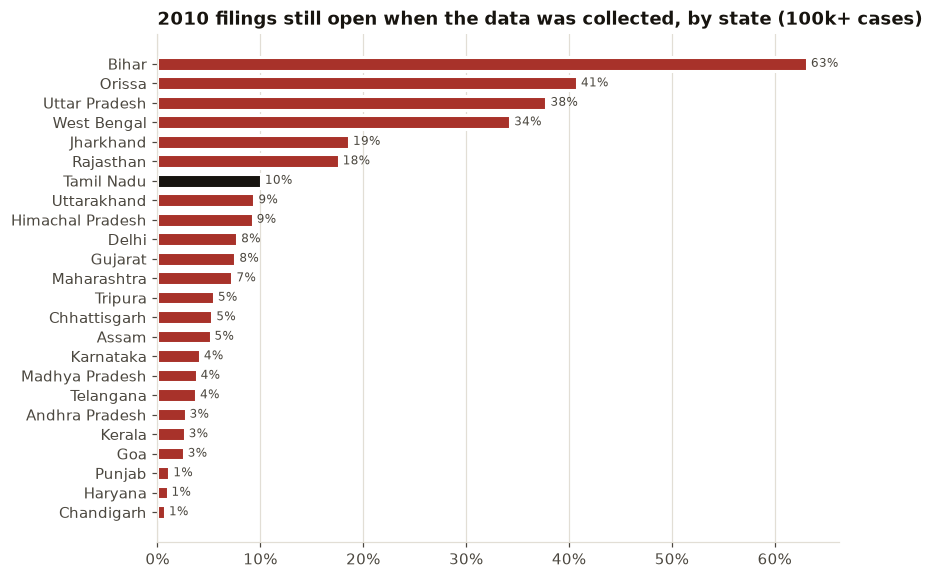

Takeaway: the typical days among finished cases fall from 1,366 days (2010) to 17 (2017) only because slow recent cases have not finished. Finished within a year: 98% for criminal miscellaneous petition vs 12% for motor accident claim; districts range 19% (Perambalur) to 74% (Theni).


In [10]:
from courtcases.glossary import CASE_TYPES
from courtcases.survival import kaplan_meier, median_days

# 1. the median trap
rows_ = []
for y, part in usable.groupby("filing_year"):
    rows_.append({"filing_year": y,
                  "median among decided cases": part.loc[part["ended"], "observed_days"].median(),
                  "Kaplan-Meier median (all cases)": median_days(kaplan_meier(part["observed_days"], part["ended"]))})
medians = pd.DataFrame(rows_).set_index("filing_year")
check("median days among decided, 2010 filings", medians.iloc[0, 0], tn["survivorship"]["median_days_among_decided"]["2010"], tol=0.5)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(medians.index, medians.iloc[:, 0], marker="o", color=ps.SERIES[1])
ax.plot(medians.index, medians.iloc[:, 1], marker="o", color=ps.SERIES[0])
ax.annotate("median among decided cases (biased)", (medians.index[0], medians.iloc[0, 0]),
            xytext=(8, 0), textcoords="offset points", va="center", fontsize=9, color=ps.SERIES[1])
ax.annotate("Kaplan-Meier median, all cases", (medians.index[0], medians.iloc[0, 1]),
            xytext=(8, -10), textcoords="offset points", va="center", fontsize=9, color=ps.SERIES[0])
ax.set_title("Median days to disposal by filing year, Tamil Nadu (two ways of counting)")
ax.set_ylabel("days")
ax.set_xticks(medians.index)
plt.show()

# 2-3. within a year by kind of case, court level and district (eligible 2015-2017 filings)
el = lab[elig].assign(within_1y=honest[elig])
by_type = el[el["type"].isin(["stc", "os", "cc", "mcop", "crlmp", "ep", "hmop", "op"])].groupby("type")["within_1y"].mean()
check("within a year, calendar cases (cc)", by_type["cc"], next(r["mean"] for r in tn["within_1y_by_type"] if r["type"] == "cc"))
fig, ax = plt.subplots(figsize=(8, 3.8))
ps.hbar(ax, [CASE_TYPES.get(t, t).split(" (")[0] + f" ({t})" for t in by_type.index], list(by_type.values))
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_title("Disposed of within a year, by kind of case (Tamil Nadu filings 2015-2017)")
plt.show()

by_court = el.groupby("court_level")["within_1y"].agg(["mean", "size"])
by_court = by_court[by_court["size"] >= 2000]
fig, ax = plt.subplots(figsize=(8, 4.2))
ps.hbar(ax, list(by_court.index), list(by_court["mean"]))
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_title("Disposed of within a year, by court level (2015-2017, levels with 2,000+ cases)")
plt.show()

district_names = key("cases_district_key.csv").query("state_code == '10'").sort_values("year")
district_names = dict(zip(district_names["dist_code"], district_names["district_name"], strict=True))
by_district = el["dist_code"].map(district_names).to_frame("district").assign(y=el["within_1y"]).groupby("district")["y"].mean()
fig, ax = plt.subplots(figsize=(8, 7.5))
ps.hbar(ax, list(by_district.index), list(by_district.values), highlight={"Chennai"})
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_title("Disposed of within a year, by district (2015-2017; Chennai highlighted)")
plt.show()

# 4. by state, 2010 filings still open at each state's cutoff (from scripts/analyse.py; the national
#    files are 81 million rows, so this one is read from the report rather than recomputed here)
states = pd.DataFrame(nat["states"]).dropna(subset=["pending_2010_filings"]).query("cases > 100_000")
fig, ax = plt.subplots(figsize=(8, 6))
ps.hbar(ax, list(states["state"]), list(states["pending_2010_filings"]), highlight={"Tamil Nadu"})
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_title("2010 filings still open when the data was collected, by state (100k+ cases)")
plt.show()

print(f"Takeaway: the typical days among finished cases fall from {medians.iloc[0, 0]:,.0f} days (2010) to "
      f"{medians.loc[2017].iloc[0]:,.0f} (2017) only because slow recent cases have not finished. Finished within a year: "
      f"{by_type.max():.0%} for {CASE_TYPES[by_type.idxmax()].split(' (')[0].lower()} vs {by_type.min():.0%} for "
      f"{CASE_TYPES[by_type.idxmin()].split(' (')[0].lower()}; districts range {by_district.min():.0%} "
      f"({by_district.idxmin()}) to {by_district.max():.0%} ({by_district.idxmax()}).")

## A9 · Where the time goes in a real dispute

**What.** Steps A1–A8 show *how long* cases take. This step looks at *where* the time goes, for
**real disputes**: every case except petty-offence cases and bail-type petitions, which usually end
in days. We split each case at its first hearing:

- **Waiting for the first hearing:** from filing to the first hearing.
- **After the first hearing:** from the first hearing to the end, using Kaplan–Meier so that cases
  still going are counted, not dropped.

We also look at the gap between a case's last hearing and its next hearing date, and at the stage
each case had reached at its last hearing, for cases still pending when the data was collected.

**Why the model can't use this.** Hearing dates happen after filing. Using them to predict on the
filing day would be cheating, so we use them here only to describe what happens.

**Data quality.** Checked first (cases filed 2015–2017): 4.7% of first-hearing dates are blank and
0.3% are before the filing date (both left out here). In 80% of finished cases, the last hearing
date is the same as the decision date. The data has only one gap between hearings for each case, so
the number of hearings below is a rough estimate.

  [agrees] median days to first hearing, real disputes: notebook 40.0000, report 40.0000
  [agrees] median days after first hearing, real disputes: notebook 808.0000, report 808.0000
  [agrees] median gap between hearings, real disputes: notebook 44.0000, report 44.0000


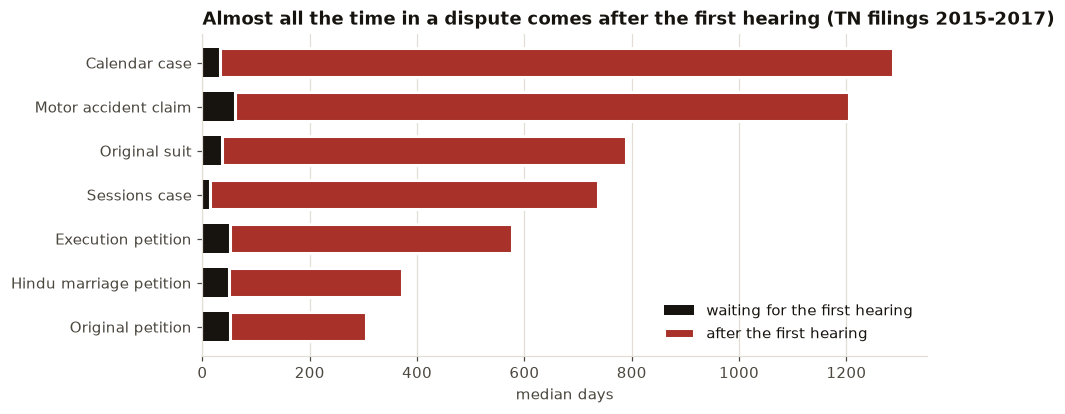

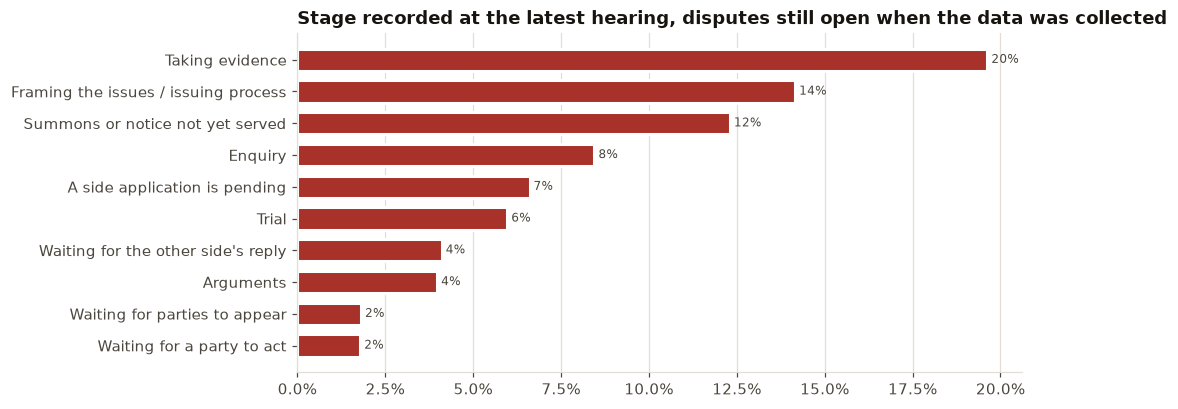

Takeaway: a real dispute waits a typical 40 days for its first hearing, then goes on for a typical 808 days more, so 95% of its time comes after the first hearing. With about 44 days between hearing dates, that is very roughly 18 hearing dates. Pending disputes are most often at the stage of: taking evidence (20%), framing the issues / issuing process (14%), summons or notice not yet served (12%).


In [11]:
from courtcases.difficulty import EASY_TYPES, hearing_gap, stage_days, stage_summary, stuck_at
from courtcases.glossary import PURPOSE_PLAIN

recent = usable[usable["filing_year"].between(2015, 2017)]
hard = recent[~recent["type"].isin(EASY_TYPES)]
stages = stage_days(hard)
overall = stage_summary(stages)
gap = hearing_gap(hard)
check("median days to first hearing, real disputes", overall["median_wait_first_hearing"],
      H["stages"]["contested"]["median_wait_first_hearing"])
check("median days after first hearing, real disputes", overall["median_after_first_hearing"],
      H["stages"]["contested"]["median_after_first_hearing"])
check("median gap between hearings, real disputes", gap.median(),
      H["stages"]["contested"]["median_gap_between_hearings"])

rows = [{"case type": CASE_TYPES.get(t, t.upper()).split(" (")[0],
         **stage_summary(stages.loc[part.index])}
        for t, part in hard.groupby("type") if len(part) >= 30_000]
by_stage = pd.DataFrame(rows).dropna(subset=["median_after_first_hearing"]).sort_values("median_after_first_hearing")
fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.barh(by_stage["case type"], by_stage["median_wait_first_hearing"], color=ps.SERIES[1], height=0.65, label="waiting for the first hearing")
ax.barh(by_stage["case type"], by_stage["median_after_first_hearing"], left=by_stage["median_wait_first_hearing"], color=ps.SERIES[0],
        height=0.65, label="after the first hearing", edgecolor=ps.SURFACE, linewidth=2)
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
ax.set_xlabel("median days")
ax.set_title("Almost all the time in a dispute comes after the first hearing (TN filings 2015-2017)")
plt.show()

top = pd.DataFrame(stuck_at(hard))
top["stage"] = top["purpose"].map(PURPOSE_PLAIN).fillna(top["purpose"])
fig, ax = plt.subplots(figsize=(8.5, 4))
ps.hbar(ax, list(top["stage"]), list(top["share"]))
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_title("Stage recorded at the latest hearing, disputes still open when the data was collected")
plt.show()

after, wait, each = overall["median_after_first_hearing"], overall["median_wait_first_hearing"], gap.median()
print(f"Takeaway: a real dispute waits a typical {wait:.0f} days for its first hearing, then goes on for a typical {after:,.0f} days more, "
      f"so {after / (after + wait):.0%} of its time comes after the first hearing. With about {each:.0f} days between hearing dates, "
      f"that is very roughly {after / each:.0f} hearing dates. Pending disputes are most often at the stage of: "
      f"{top['stage'].iloc[0].lower()} ({top['share'].iloc[0]:.0%}), {top['stage'].iloc[1].lower()} ({top['share'].iloc[1]:.0%}), "
      f"{top['stage'].iloc[2].lower()} ({top['share'].iloc[2]:.0%}).")

# Part B · The machine-learning pipeline

## B1 · The inputs: only what is known on filing day

**What.** Each case is turned into 12 inputs (`features.build` and `features.add_law`), in two groups:

*Basic filing facts*
- the district, the type of court, the type of case (the court's own code, for example `os` = civil
  suit, `cc` = a criminal case before a magistrate) and the month of filing;
- how busy the courts are, using only earlier cases: how many cases were already pending in that
  district's courts of that type on the filing day, how many they finished in the year before, and
  how many cases of the same type were filed there the year before. (We use the logarithm of these
  counts, so going from 10 to 100 counts as much as going from 100 to 1,000.)

*The law and section* (what the case was filed under)
- the law, the law and section together (the 40 most common, for example "Negotiable Instruments
  Act section 138" = a bounced cheque), whether the offence is bailable, whether the case is criminal
  or civil, and how many sections of the Indian Penal Code were charged.

**What we left out on purpose.** Hearing dates and what each hearing was for (they come from the
case's *future*), the decision date and how the case ended (that is the answer itself), the gender of
the people in the case (a public tool should not judge a case by gender), and the court number (a
visitor can't know which numbered court will get the case).

**Why this matters.** If a model sees information from the future, its test scores look great but it
fails in real use. This mistake is called *leakage*. For the same reason, the list of case types and
sections the model knows is decided using the training years only.

In [12]:
from courtcases.features import FEATURE_SETS
from courtcases.modelling import TRAIN_YEARS, modelling_data

for name, (cats, nums) in FEATURE_SETS.items():
    print(f"{name:>18}: {len(cats) + len(nums)} inputs = categorical {cats} + numeric {nums}")

t0 = time.time()
data = modelling_data(lab)   # the same function train_within_1y.py and experiments.py use
frame = data.frame
print(f"\nFeature table built in {time.time() - t0:.0f}s: {len(frame):,} usable cases, {frame.shape[1]} columns "
      f"(vocabularies decided on {TRAIN_YEARS}: {len(data.case_types)} case types, {len(data.sections)} law+section pairs)")
display(frame[frame["filing_year"] == 2017].sample(4, random_state=2).T)
print("Takeaway: 12 inputs, all known on the day of filing; nothing from later in the case.")

     filing basics: 7 inputs = categorical ['district', 'court_level', 'case_type', 'filing_month'] + numeric ['log_prev_year_filings', 'log_pending_at_filing', 'clearance_last_year']
 + law and section: 12 inputs = categorical ['district', 'court_level', 'case_type', 'filing_month', 'law', 'law_section', 'ipc_bailable', 'criminal'] + numeric ['log_prev_year_filings', 'log_pending_at_filing', 'clearance_last_year', 'n_ipc_sections']



Feature table built in 10s: 3,614,963 usable cases, 14 columns (vocabularies decided on (2015, 2016): 38 case types, 40 law+section pairs)


,2498064,2746541,2456664,2601716
district,Tiruchirappalli,Coimbatore,Nagapattinam,Chennai
court_level,Munsif court,Sub court (subordinate judge),Munsif court,Small cause court
case_type,os,ep,os,mcop
filing_month,12,3,6,6
log_prev_year_filings,8.429891,7.465655,6.875232,9.049232
log_pending_at_filing,9.133891,9.142811,7.664816,10.401501
clearance_last_year,0.333333,0.291537,0.435741,0.333435
filing_year,2017,2017,2017,2017
within_1y,1.0,0.0,0.0,0.0
law,Code of Civil Procedure,Code of Civil Procedure,Code of Civil Procedure,Motor Vehicles Act


Takeaway: 12 inputs, all known on the day of filing; nothing from later in the case.


## B2 · The time split: learn from the past, test on a later year

**What.** The models learn from cases filed in **2015**; we use cases filed in **2016** to pick the
best one; the winner then learns again from 2015 and 2016 together and is tested **once** on cases
filed in **2017**, which it has never seen. Cases from 2010–2014 are left out (step A6).

**Why not mix the years randomly.** The model will be used on *future* cases. If we mixed the years,
the model would learn things about 2017 (such as how fast courts had become that year) and look
better than it really is. Testing on a later year is the fair test, and it also shows whether things
change over time (step B12).

In [13]:
model_rows = frame[frame["within_1y"].notna() & frame["filing_year"].between(2015, 2017)]
fit_part = model_rows[model_rows["filing_year"] == 2015]       # train candidates
choose_part = model_rows[model_rows["filing_year"] == 2016]    # choose between them
final_train = model_rows[model_rows["filing_year"] <= 2016]    # refit the winner
test = model_rows[model_rows["filing_year"] == 2017]           # test once

split = pd.DataFrame({"role": ["train candidates", "choose the model", "refit the winner", "test once (unseen)"],
                      "filing years": ["2015", "2016", "2015-2016", "2017"],
                      "cases": [len(fit_part), len(choose_part), len(final_train), len(test)],
                      "share within a year": [p["within_1y"].mean() for p in (fit_part, choose_part, final_train, test)]})
display(split.set_index("role").style.format({"cases": "{:,}", "share within a year": "{:.1%}"}))
check("2017 test cases", len(test), R["test"]["baseline: overall rate"]["n"], tol=0.5)
print(f"Takeaway: {len(final_train):,} cases to learn from, {len(test):,} later cases to test on; "
      f"the share finishing within a year rises every year ({fit_part['within_1y'].mean():.0%} -> "
      f"{choose_part['within_1y'].mean():.0%} -> {test['within_1y'].mean():.0%}), which mixing the years randomly would hide.")

,filing years,cases,share within a year
role,,,
train candidates,2015,"405,062",35.9%
choose the model,2016,"445,639",43.5%
refit the winner,2015-2016,"850,701",39.8%
test once (unseen),2017,"549,273",49.5%


  [agrees] 2017 test cases: notebook 549,273.0000, report 549,273.0000
Takeaway: 850,701 cases to learn from, 549,273 later cases to test on; the share finishing within a year rises every year (36% -> 43% -> 49%), which mixing the years randomly would hide.


## B3 · Simple rules to beat, and how we score a prediction

**What.** Three simple rules (baselines) that any model must beat. Each learns from 2015–2016 and is
tested on 2017:

1. **Overall rate:** give every case the same chance.
2. **Rate by case type:** look up the share for that type of case.
3. **Rate by case type and district:** a look-up table by type of case and district. (Small groups
   are pulled towards the overall rate, so a group of three cases can't give a silly answer.)

**How we score predictions.** For each case the model gives a *chance* (a probability) of finishing
within a year.

- **Accuracy:** say "yes" when the chance is 50% or more, and count how often that is right.
- **AUC:** pick one case that finished within a year and one that didn't. AUC is how often the model
  gives the first one the higher chance. 0.5 is guessing, 1.0 is perfect.
- **Brier score:** how far the chances are from what really happened (the average of (chance −
  result)², where the result is 1 or 0). Lower is better; always saying 50% gives 0.25.
- **Log loss:** also lower is better, but it punishes confident mistakes much more (for example,
  saying 95% for a case that dragged on). We used log loss to *choose* the model.

In [14]:
# the project's own scoring functions, from scripts/train_within_1y.py
from train_within_1y import lookup, metrics

y_train, y_test = final_train["within_1y"].astype(int).to_numpy(), test["within_1y"].astype(int).to_numpy()
baselines = {
    "baseline: overall rate": np.full(len(test), final_train["within_1y"].mean()),
    "baseline: rate per case type": lookup(final_train, test, ["case_type"]),
    "baseline: rate per case type x district": lookup(final_train, test, ["case_type", "district"]),
}
scores = {name: metrics(y_test, p) for name, p in baselines.items()}
for name, s in scores.items():
    check(f"{name}: 2017 AUC", s["auc"], R["test"][name]["auc"])
display(pd.DataFrame(scores).T[["accuracy", "auc", "brier", "log_loss"]].style.format("{:.3f}"))
print(f"Takeaway: knowing only the type of case already gives an AUC of {scores['baseline: rate per case type']['auc']:.3f}; "
      f"adding the district raises it to {scores['baseline: rate per case type x district']['auc']:.3f}. "
      f"A model has to beat this look-up table to be worth using.")

  [agrees] baseline: overall rate: 2017 AUC: notebook 0.5000, report 0.5000
  [agrees] baseline: rate per case type: 2017 AUC: notebook 0.8275, report 0.8275
  [agrees] baseline: rate per case type x district: 2017 AUC: notebook 0.8439, report 0.8439


,accuracy,auc,brier,log_loss
baseline: overall rate,0.505,0.500,0.259,0.712
baseline: rate per case type,0.780,0.828,0.163,0.502
baseline: rate per case type x district,0.759,0.844,0.163,0.492


Takeaway: knowing only the type of case already gives an AUC of 0.828; adding the district raises it to 0.844. A model has to beat this look-up table to be worth using.


## B4 · Three kinds of model, with and without the law inputs

**What.** We tried three kinds of model, each with a few settings, on both groups of inputs
(`scripts/train_within_1y.py`):

- **Logistic regression:** gives each input a weight, adds them up, and turns the total into a
  chance between 0 and 1. Simple, fast, and you can read what each weight means. (Each category, such
  as a district, becomes its own 0/1 column.)
- **Linear SVM:** draws the straight line that best separates "finished within a year" from "did
  not". Its scores are then turned into chances.
- **Random forest:** hundreds of decision trees, each built on a random sample of cases, that vote
  together. It can find combinations of inputs by itself.

Each learned from 2015 and was scored on 2016; the best setting of each then learned from 2015–2016
and was tested on 2017. The random forests take minutes, so their results are read from
`reports/within_1y_results.json`. Logistic regression is fast, so we **train it again here** and
check that it gives the same result as the report.

logistic regression (+ law and section, C=1.0) refitted on 2015-2016 in 3s
  [agrees] live logistic regression 2017 auc: notebook 0.8735, report 0.8735
  [agrees] live logistic regression 2017 brier: notebook 0.1376, report 0.1376
  [agrees] live logistic regression 2017 log_loss: notebook 0.4274, report 0.4274
  [agrees] live logistic regression 2017 accuracy: notebook 0.8086, report 0.8086


,accuracy,auc,brier,log_loss,source
Baseline: overall rate,0.505,0.500,0.259,0.712,computed above
Baseline: rate per case type,0.780,0.828,0.163,0.502,computed above
Baseline: case type x district lookup,0.759,0.844,0.163,0.492,computed above
"Logistic regression, filing basics",0.780,0.842,0.158,0.483,reports/within_1y_results.json
"Linear SVM, filing basics",0.782,0.843,0.157,0.481,reports/within_1y_results.json
"Random forest, filing basics",0.777,0.847,0.159,0.488,reports/within_1y_results.json
"Logistic regression, with law and section (served)",0.809,0.873,0.138,0.427,computed above
"Linear SVM, with law and section",0.811,0.873,0.137,0.429,reports/within_1y_results.json
"Random forest, with law and section",0.807,0.874,0.138,0.428,reports/within_1y_results.json


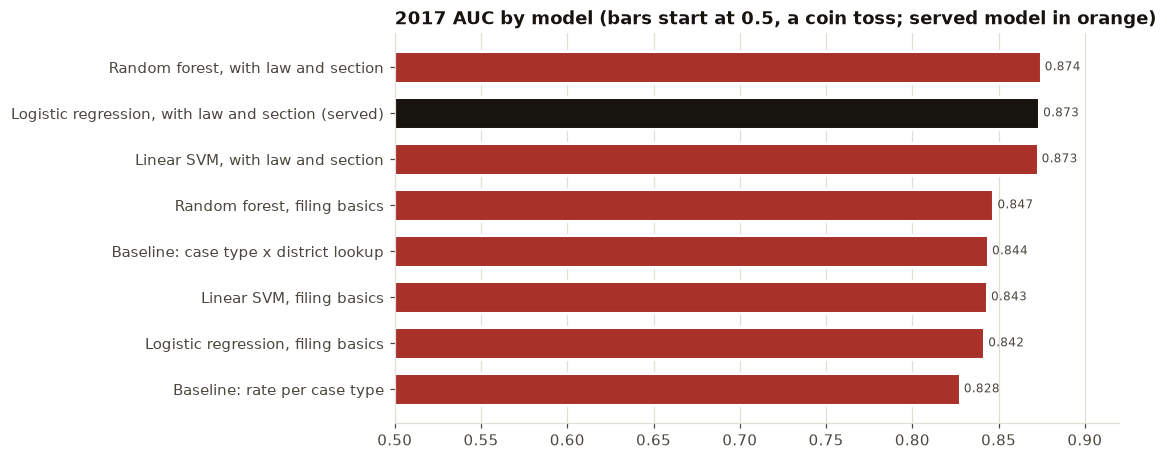

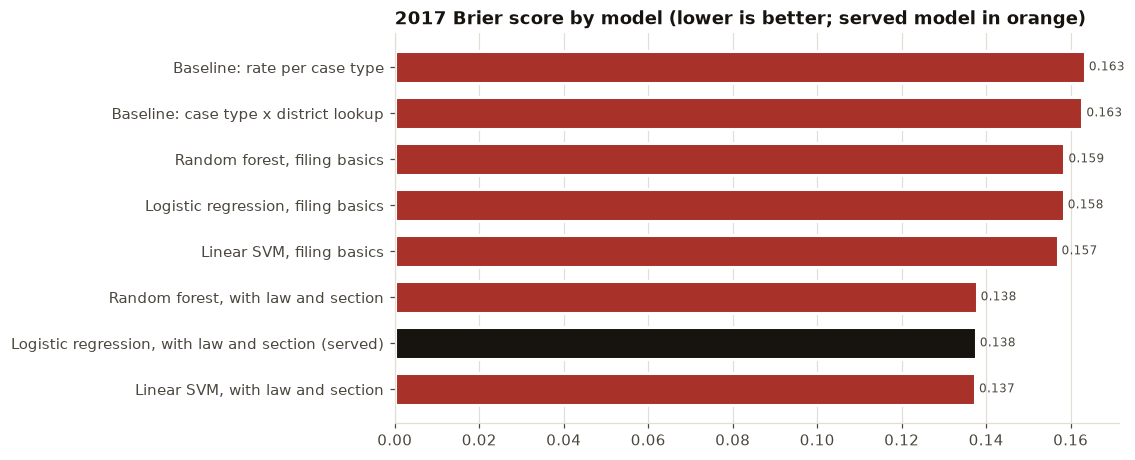

Takeaway: without the law inputs the best model reaches an AUC of 0.847, only just above the look-up table (0.844); with them, all three kinds of model reach 0.873-0.874 (Brier about 0.138). Knowing what the case is about helps; which model we use hardly matters.


In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from train_within_1y import one_hot

CATS, NUMS = FEATURE_SETS["+ law and section"]
t0 = time.time()
lr_live = Pipeline([("prep", one_hot(CATS, NUMS)), ("model", LogisticRegression(C=1.0, max_iter=3000))])
lr_live.fit(final_train[CATS + NUMS], y_train)
p_live = lr_live.predict_proba(test[CATS + NUMS])[:, 1]
live = metrics(y_test, p_live)
print(f"logistic regression (+ law and section, C=1.0) refitted on 2015-2016 in {time.time() - t0:.0f}s")
for m in ("auc", "brier", "log_loss", "accuracy"):
    check(f"live logistic regression 2017 {m}", live[m], R["test"][META["model"]][m])


def short(name):
    base = {"baseline: overall rate": "Baseline: overall rate",
            "baseline: rate per case type": "Baseline: rate per case type",
            "baseline: rate per case type x district": "Baseline: case type x district lookup"}
    if name in base:
        return base[name]
    inputs, rest = name.split(" | ")
    family = rest.split(" (")[0].replace(" (calibrated)", "").replace("linear SVM", "Linear SVM")
    family = family[0].upper() + family[1:]
    return f"{family}, {'filing basics' if inputs == 'filing basics' else 'with law and section'}"


comparison = pd.DataFrame(R["test"]).T[["accuracy", "auc", "brier", "log_loss"]].astype(float)
comparison.index = [short(n) + (" (served)" if n == META["model"] else "") for n in comparison.index]
comparison["source"] = ["computed above" if "Baseline" in n or "served" in n else "reports/within_1y_results.json"
                        for n in comparison.index]
display(comparison.style.format("{:.3f}", subset=["accuracy", "auc", "brier", "log_loss"])
        .highlight_max(subset=["accuracy", "auc"], color=ps.RAMP[0])
        .highlight_min(subset=["brier", "log_loss"], color=ps.RAMP[0]))

fig, ax = plt.subplots(figsize=(8.5, 4.6))
auc = comparison["auc"].drop("Baseline: overall rate")
ps.hbar(ax, list(auc.index), list(auc.values), fmt="{:.3f}", highlight={n for n in auc.index if "served" in n})
ax.set_xlim(0.5, 0.92)
ax.set_title("2017 AUC by model (bars start at 0.5, a coin toss; served model in orange)")
plt.show()

fig, ax = plt.subplots(figsize=(8.5, 4.6))
brier = comparison["brier"].drop("Baseline: overall rate")
ps.hbar(ax, list(brier.index), list(brier.values), fmt="{:.3f}", highlight={n for n in brier.index if "served" in n})
ax.set_title("2017 Brier score by model (lower is better; served model in orange)")
plt.show()

basics = comparison[comparison.index.str.contains("filing basics")]
with_law = comparison[comparison.index.str.contains("law and section")]
print(f"Takeaway: without the law inputs the best model reaches an AUC of {basics['auc'].max():.3f}, only just above the "
      f"look-up table ({comparison.loc['Baseline: case type x district lookup', 'auc']:.3f}); with them, all three "
      f"kinds of model reach {with_law['auc'].min():.3f}-{with_law['auc'].max():.3f} (Brier about {with_law['brier'].mean():.3f}). "
      f"Knowing what the case is about helps; which model we use hardly matters.")

## B5 · The model we chose, and why

**What.** We set the rule *before* looking at 2017: use whichever model had the **lowest log loss on
2016** after learning from 2015. That was logistic regression with the law inputs (with the setting
C = 1.0, which controls how strongly the weights are kept small).

**Why not the random forest**, which scores slightly higher on 2017? Because we chose on 2016.
Picking a model by its 2017 score would turn the test into part of the training, and the test would
no longer be fair. Logistic regression is also tiny (6 kB), very fast, and its weights explain each
prediction exactly ("this input raised the chance by this much"), which the website shows.

Below, the saved model file (`artifacts/within_1y/model.joblib`) is loaded and compared with the one
trained in B4: they should give the same predictions.

In [16]:
selection = pd.DataFrame(R["selection"]).T[["log_loss", "auc", "brier"]].astype(float).sort_values("log_loss")
selection.index = [n.replace("baseline: ", "Baseline: ") for n in selection.index]
print("Model selection: trained on 2015, scored on 2016, best log loss first")
display(selection.head(8).style.format("{:.4f}"))
chosen = min(R["selection"], key=lambda n: R["selection"][n]["log_loss"])
print(f"Chosen (lowest 2016 log loss): {chosen}\nServed model in metadata.json: {META['model']}")

served = joblib.load(ARTIFACT / "model.joblib")
p_test = served.predict_proba(test[CATS + NUMS])[:, 1]
print(f"\nSaved model file: {(ARTIFACT / 'model.joblib').stat().st_size / 1e3:.0f} kB, scikit-learn {META['scikit_learn']}")
print(f"Largest difference between the saved model's and the live refit's 2017 probabilities: {np.abs(p_test - p_live).max():.2e}")
print(f"Takeaway: the chosen model is {short(META['model'])}, picked on 2016 before 2017 was looked at; "
      f"the saved file gives exactly the same results.")

Model selection: trained on 2015, scored on 2016, best log loss first


,log_loss,auc,brier
+ law and section | logistic regression (C=1.0),0.4312,0.8708,0.1376
+ law and section | logistic regression (C=0.1),0.4313,0.8711,0.1376
"+ law and section | random forest (min_samples_leaf=300, max_features=sqrt)",0.4666,0.8718,0.1497
"+ law and section | random forest (min_samples_leaf=300, max_features=None)",0.4690,0.8491,0.1533
filing basics | logistic regression (C=0.1),0.4954,0.8325,0.1631
filing basics | logistic regression (C=1.0),0.4955,0.8322,0.1631
Baseline: rate per case type,0.5127,0.8126,0.1690
+ law and section | linear SVM (calibrated) (C=0.01),0.5270,0.8613,0.1726


Chosen (lowest 2016 log loss): + law and section | logistic regression (C=1.0)
Served model in metadata.json: + law and section | logistic regression (C=1.0)



Saved model file: 6 kB, scikit-learn 1.9.1
Largest difference between the saved model's and the live refit's 2017 probabilities: 0.00e+00
Takeaway: the chosen model is Logistic regression, with law and section, picked on 2016 before 2017 was looked at; the saved file gives exactly the same results.


## B6 · Testing on 549,273 new 2017 cases

**What.** The chosen model's chance for every 2017 case, scored in the four ways from B3, plus:

- a **confusion matrix:** if we say "yes" at 50%, how many cases were rightly called yes, wrongly
  called yes, wrongly called no, and rightly called no;
- a **calibration curve:** put cases into groups by their predicted chance (0–10%, 10–20%, …) and
  compare the average chance in each group with how many really finished within a year. Points on
  the diagonal line mean "when the model says 70%, it really happens about 70% of the time".

2017 test, 549,273 cases, 49.5% actually finished within a year
  accuracy 0.809   AUC 0.873   Brier 0.138   log loss 0.427   F1 0.786
  [agrees] served model 2017 accuracy: notebook 0.8086, report 0.8086
  [agrees] served model 2017 auc: notebook 0.8735, report 0.8735
  [agrees] served model 2017 brier: notebook 0.1376, report 0.1376
  [agrees] served model 2017 log_loss: notebook 0.4274, report 0.4274


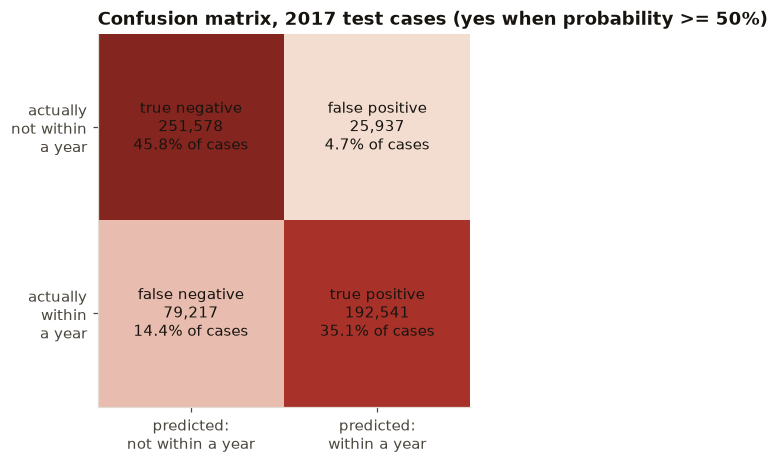

precision (when it says yes, how often right): 88.1%;  recall (of cases that did finish within a year, how many it called yes): 70.9%


  [agrees] calibration: observed share in the 0.5-0.6 bin: notebook 0.5581, report 0.5581


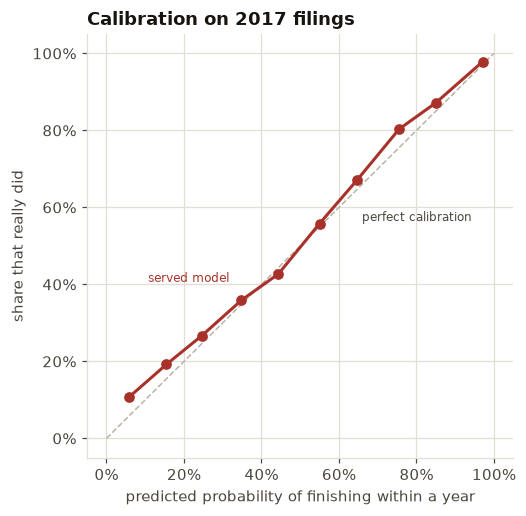

,predicted range,cases,mean prediction,really finished within a year
0,0.0-0.1,"71,727",5.7%,10.6%
1,0.1-0.2,"97,336",15.5%,19.2%
2,0.2-0.3,"77,890",24.6%,26.7%
3,0.3-0.4,"54,450",34.8%,35.9%
4,0.4-0.5,"29,392",44.4%,42.7%
5,0.5-0.6,"21,384",55.0%,55.8%
6,0.6-0.7,"17,825",64.8%,67.2%
7,0.7-0.8,"20,722",75.5%,80.4%
8,0.8-0.9,"29,448",85.0%,87.2%
9,0.9-1.0,"129,099",97.1%,97.8%


Takeaway: right 81% of the time (8 in 10), AUC 0.873 against 0.844 for the look-up table, Brier 0.138 against 0.163; its chances match reality (a predicted 55% happened 56% of the time).


In [17]:
from sklearn.metrics import confusion_matrix
from train_within_1y import calibration_table

final = metrics(y_test, p_test)
print(f"2017 test, {final['n']:,} cases, {final['positive_rate']:.1%} actually finished within a year")
print(f"  accuracy {final['accuracy']:.3f}   AUC {final['auc']:.3f}   Brier {final['brier']:.3f}   log loss {final['log_loss']:.3f}   F1 {final['f1']:.3f}")
for m in ("accuracy", "auc", "brier", "log_loss"):
    check(f"served model 2017 {m}", final[m], META["test_metrics"][m])

cm = confusion_matrix(y_test, p_test >= 0.5)
tn_, fp_, fn_, tp_ = cm.ravel()
fig, ax = plt.subplots(figsize=(5.2, 4.4))
ax.imshow(cm, cmap=plt.matplotlib.colors.ListedColormap(ps.RAMP), vmin=0, vmax=cm.max() * 1.3)
labels = [["true negative", "false positive"], ["false negative", "true positive"]]
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{labels[i][j]}\n{cm[i, j]:,}\n{cm[i, j] / cm.sum():.1%} of cases", ha="center", va="center",
                fontsize=10, color=ps.INK)
ax.set_xticks([0, 1], ["predicted:\nnot within a year", "predicted:\nwithin a year"])
ax.set_yticks([0, 1], ["actually\nnot within\na year", "actually\nwithin\na year"])
ax.grid(False)
ax.set_title("Confusion matrix, 2017 test cases (yes when probability >= 50%)")
plt.show()
print(f"precision (when it says yes, how often right): {tp_ / (tp_ + fp_):.1%};  "
      f"recall (of cases that did finish within a year, how many it called yes): {tp_ / (tp_ + fn_):.1%}")

cal = pd.DataFrame(calibration_table(y_test, p_test))
reported = pd.DataFrame(R["served"]["calibration_2017"])
check("calibration: observed share in the 0.5-0.6 bin", cal.loc[cal.predicted == "0.5-0.6", "observed"].iloc[0],
      reported.loc[reported.predicted == "0.5-0.6", "observed"].iloc[0])
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, 1], [0, 1], color=ps.NEUTRAL, lw=1, ls="--")
ax.plot(cal["mean_predicted"], cal["observed"], marker="o", color=ps.SERIES[0])
ax.annotate("perfect calibration", (0.62, 0.62), xytext=(10, -14), textcoords="offset points", fontsize=8, color=ps.INK_2)
ax.annotate("served model", (cal["mean_predicted"].iloc[3], cal["observed"].iloc[3]), xytext=(-8, 12),
            textcoords="offset points", fontsize=8, color=ps.SERIES[0], ha="right")
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlabel("predicted probability of finishing within a year")
ax.set_ylabel("share that really did")
ax.set_title("Calibration on 2017 filings")
plt.show()
display(cal.rename(columns={"predicted": "predicted range", "cases": "cases", "mean_predicted": "mean prediction",
                            "observed": "really finished within a year"})
        .style.format({"cases": "{:,}", "mean prediction": "{:.1%}", "really finished within a year": "{:.1%}"}))

print(f"Takeaway: right {final['accuracy']:.0%} of the time ({final['accuracy'] * 10:.0f} in 10), AUC {final['auc']:.3f} against "
      f"{scores['baseline: rate per case type x district']['auc']:.3f} for the look-up table, Brier {final['brier']:.3f} against "
      f"{scores['baseline: rate per case type x district']['brier']:.3f}; its chances match reality "
      f"(a predicted {cal['mean_predicted'].iloc[5]:.0%} happened {cal['observed'].iloc[5]:.0%} of the time).")

## B7 · How much of that accuracy comes from easy cases?

**What.** The accuracy above is over *all* cases, and that hides something important. Petty-offence
cases and bail-type petitions almost always finish within a year, so almost any model gets them
right. Here we score the same predictions separately for these **easy cases** and for **real
disputes** (everything else), and compare each with the simplest rule: **always guess the most
common answer for that group**.

**Why.** A model is only useful if it beats that rule. If we reported only the overall accuracy, we
would be overselling what the filing-day information can do.

**Could a better model fix it?** We also trained logistic regression and a random forest on real
disputes only. If they did much better, the problem would be the model. If not, the information
simply isn't there on the filing day.

  [agrees] accuracy, all cases: notebook 0.8086, report 0.8086
  [agrees] accuracy, easy cases: notebook 0.9264, report 0.9264
  [agrees] accuracy, contested cases: notebook 0.7431, report 0.7431


group,cases,model accuracy,always guess the commonest answer,AUC
All 2017 test cases,"549,273",80.9%,50.5%,0.873
Easy: summary trials and bail-type petitions,"196,105",92.6%,88.1%,0.903
Real disputes (everything else),"353,168",74.3%,72.0%,0.706


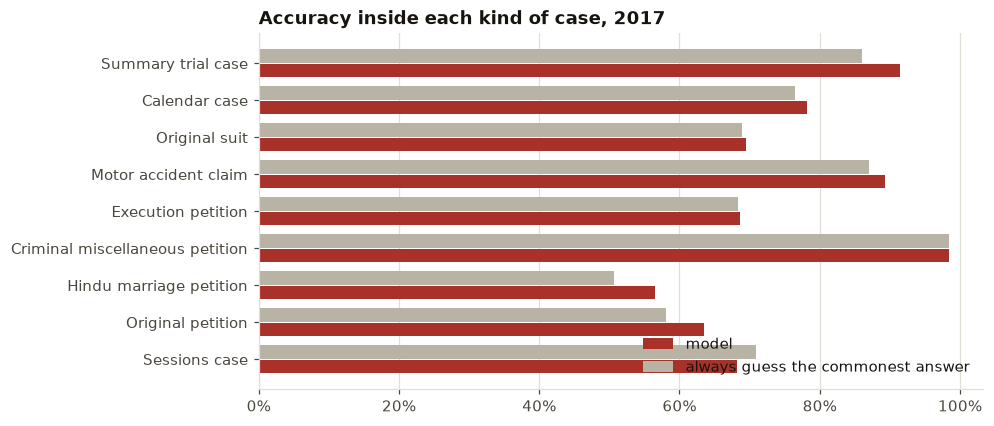

,auc,accuracy
"logistic regression, trained on real disputes only",0.713,74.7%
"random forest, trained on real disputes only",0.722,74.3%


Takeaway: the overall 80.9% mostly comes from telling easy cases apart from hard ones. On real disputes (64% of cases) it is right 74.3% of the time, against 72.0% for always guessing 'not within a year'. Models trained only on real disputes reach an AUC of 0.72, so the limit is the information on the filing day, not the model.


In [18]:
from courtcases.difficulty import difficulty_table

scored = test.assign(y=y_test, p=p_test)
table = difficulty_table(scored)
for group in ("all", "easy", "contested"):
    check(f"accuracy, {group} cases", table[group]["accuracy"], H["difficulty"][group]["accuracy"])

names = {"all": "All 2017 test cases", "easy": "Easy: summary trials and bail-type petitions", "contested": "Real disputes (everything else)"}
view = pd.DataFrame([{"group": names[g], "cases": table[g]["n"], "model accuracy": table[g]["accuracy"],
                      "always guess the commonest answer": table[g]["majority_accuracy"], "AUC": table[g]["auc"]} for g in names])
display(view.style.format({"cases": "{:,}", "model accuracy": "{:.1%}", "always guess the commonest answer": "{:.1%}", "AUC": "{:.3f}"}).hide(axis="index"))

types = pd.DataFrame(table["by_type"])
types["case type"] = types["case_type"].map(lambda t: CASE_TYPES.get(t, t.upper()).split(" (")[0])
big = types[types["n"] >= 9000].copy()
fig, ax = plt.subplots(figsize=(8.5, 4.2))
y = np.arange(len(big))
ax.barh(y + 0.19, big["accuracy"], height=0.36, color=ps.SERIES[0], label="model")
ax.barh(y - 0.19, big["majority_accuracy"], height=0.36, color=ps.NEUTRAL, label="always guess the commonest answer")
ax.set_yticks(y, big["case type"])
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.grid(axis="y", visible=False)
ax.invert_yaxis()
ax.legend(loc="lower right")
ax.set_title("Accuracy inside each kind of case, 2017")
plt.show()

only = pd.DataFrame(H["contested_only_models"]).T
display(only.style.format({"auc": "{:.3f}", "accuracy": "{:.1%}"}))

c = table["contested"]
print(f"Takeaway: the overall {table['all']['accuracy']:.1%} mostly comes from telling easy cases apart from hard ones. On real disputes "
      f"({c['n'] / table['all']['n']:.0%} of cases) it is right {c['accuracy']:.1%} of the time, against {c['majority_accuracy']:.1%} for always "
      f"guessing 'not within a year'. Models trained only on real disputes reach an AUC of {only['auc'].max():.2f}, so the limit is the "
      f"information on the filing day, not the model.")

## B8 · What the model relies on

**What.** Two ways to see it.

- **Shuffle test (permutation importance),** from the training script, on 50,000 test cases: mix up
  one input's values between cases so that it becomes useless, and see how much worse the model gets.
  The bigger the drop, the more the model relied on that input.
- **The model's weights:** logistic regression adds up one weight per category. A positive weight
  pushes towards "finishes within a year", a negative one towards "takes longer". The biggest ones
  are listed below.

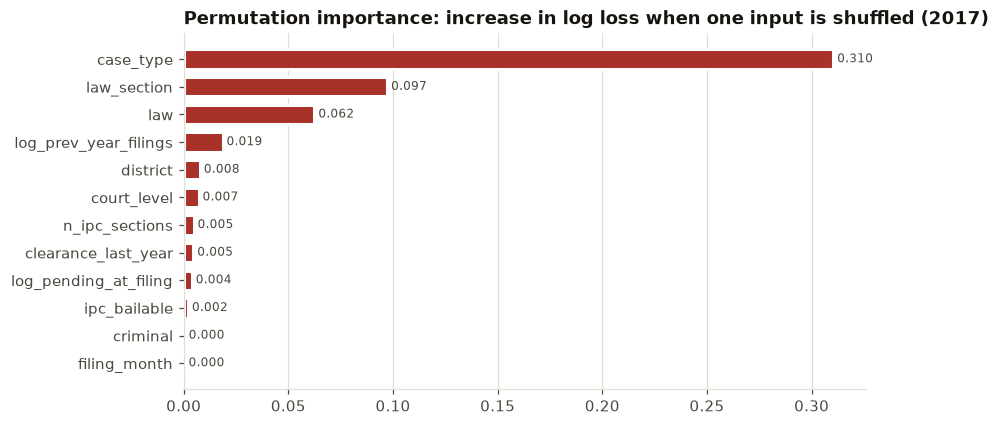

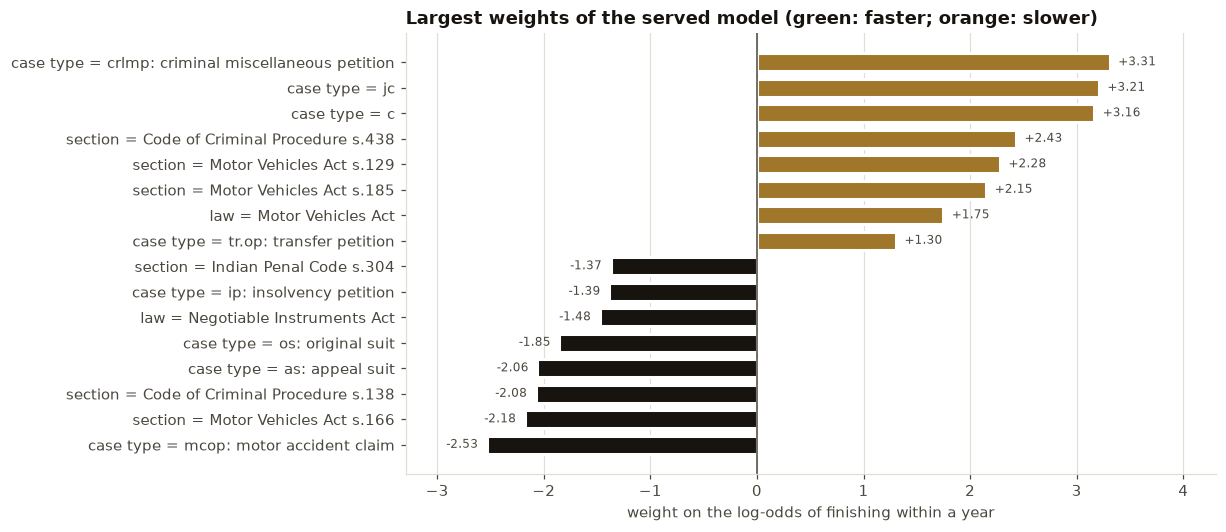

Takeaway: the type of case matters most (shuffle score 0.31, next law_section 0.10); every other input is below 0.06. The model mostly knows which types of case are quick.


In [19]:
imp = pd.Series({k: v["mean"] for k, v in R["served"]["permutation_importance_2017"].items()}).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.2))
ps.hbar(ax, list(imp.index), list(imp.values), fmt="{:.3f}")
ax.set_title("Permutation importance: increase in log loss when one input is shuffled (2017)")
plt.show()

prep, lr = served.named_steps["prep"], served.named_steps["model"]
names = list(prep.get_feature_names_out())


def readable(name):
    name = name.replace("cat__", "").replace("num__", "")
    for prefix, label in [("case_type_", "case type"), ("law_section_", "section"), ("law_", "law"),
                          ("court_level_", "court"), ("district_", "district")]:
        if name.startswith(prefix):
            value = name[len(prefix):]
            if prefix == "case_type_" and value in CASE_TYPES:
                value = f"{value}: {CASE_TYPES[value].split(' (')[0].lower()}"
            return f"{label} = {value}"
    return name


weights = pd.Series(lr.coef_[0], index=[readable(n) for n in names])
top = pd.concat([weights.nlargest(8), weights.nsmallest(8)]).sort_values()
fig, ax = plt.subplots(figsize=(9.5, 5.2))
colors = [ps.SERIES[2] if w > 0 else ps.SERIES[1] for w in top.values]
bars = ax.barh(top.index, top.values, color=colors, height=0.7, edgecolor=ps.SURFACE, linewidth=2)
for bar, w in zip(bars, top.values, strict=True):
    ax.text(w + (0.08 if w > 0 else -0.08), bar.get_y() + bar.get_height() / 2, f"{w:+.2f}",
            va="center", ha="left" if w > 0 else "right", fontsize=8, color=ps.INK_2)
ax.axvline(0, color=ps.INK_2, lw=1)
ax.grid(axis="y", visible=False)
ax.set_xlim(top.min() * 1.3, top.max() * 1.3)
ax.set_title("Largest weights of the served model (green: faster; orange: slower)")
ax.set_xlabel("weight on the log-odds of finishing within a year")
plt.show()

print(f"Takeaway: the type of case matters most (shuffle score {imp['case_type']:.2f}, next "
      f"{imp.index[-2]} {imp.iloc[-2]:.2f}); every other input is below {imp.iloc[-3]:.2f}. "
      f"The model mostly knows which types of case are quick.")

## B9 · Extra analysis: predicting the number of days (linear regression)

**What.** The main model answers yes/no because unfinished cases have no known number of days. A
regression (which predicts a number) needs finished cases, so `scripts/regress_days.py` answers a
smaller question, and says so: **for cases that finished within 730 days (two years), how many days
did they take?** It learns from 2015 cases and is tested on 2016 cases. It predicts log(1 + days),
because a few very long cases would otherwise dominate. The rule to beat is the typical (median)
number of days for that type of case.

**Why this is only a side analysis.** It only describes cases that *did* finish within two years. It
says nothing about the many that did not, so it must not be read as "how long your case will take".

,test cases,mean absolute error (days),median absolute error (days),R² on log(days)
linear regression,"251,097",116,43,0.669
baseline: median per case type,"251,097",109,51,0.611


  [agrees] regression mean absolute error (days): notebook 116.3456, report 116.3456
  [agrees] regression R² on log(days): notebook 0.6689, report 0.6689


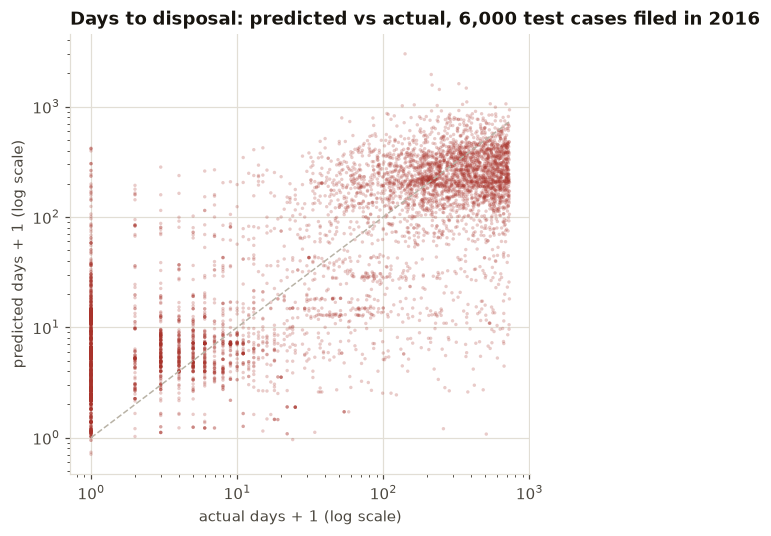

Takeaway: for cases that finished within two years, the regression is typically off by 43 days and explains 67% of the variation in log(days), better than the typical days for the case type (61%); its average error (116 days) is worse than that rule's (109) because a few very long cases pull the average up. Useful to describe the data, not to forecast.


In [20]:
from regress_days import HORIZON, report
from sklearn.linear_model import LinearRegression

finished = frame.join(lab[["observed_days", "ended"]])
finished = finished[finished["ended"] & (finished["observed_days"] <= HORIZON)]
reg_train, reg_test = finished[finished.filing_year == 2015], finished[finished.filing_year == 2016]
reg = Pipeline([("prep", one_hot(CATS, NUMS)), ("model", LinearRegression())])
reg.fit(reg_train[CATS + NUMS], np.log1p(reg_train["observed_days"]))
pred_days = np.expm1(reg.predict(reg_test[CATS + NUMS]))
base_days = reg_test["case_type"].map(reg_train.groupby("case_type")["observed_days"].median()).fillna(
    reg_train["observed_days"].median()).to_numpy()
days = reg_test["observed_days"].to_numpy()
reg_results = pd.DataFrame({"linear regression": report(days, pred_days),
                            "baseline: median per case type": report(days, base_days)}).T
reg_results.columns = ["test cases", "mean absolute error (days)", "median absolute error (days)", "R² on log(days)"]
display(reg_results.style.format({"test cases": "{:,.0f}", "mean absolute error (days)": "{:.0f}",
                                  "median absolute error (days)": "{:.0f}", "R² on log(days)": "{:.3f}"}))
check("regression mean absolute error (days)", reg_results.iloc[0, 1], D["linear_regression"]["mae_days"], tol=0.05)
check("regression R² on log(days)", reg_results.iloc[0, 3], D["linear_regression"]["r2_log_days"])

sample = reg_test.sample(6000, random_state=0).index
fig, ax = plt.subplots(figsize=(5.4, 5.2))
ax.scatter(days[reg_test.index.get_indexer(sample)] + 1, pred_days[reg_test.index.get_indexer(sample)] + 1,
           s=5, alpha=0.25, color=ps.SERIES[0], edgecolors="none")
ax.plot([1, HORIZON], [1, HORIZON], color=ps.NEUTRAL, lw=1, ls="--")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("actual days + 1 (log scale)")
ax.set_ylabel("predicted days + 1 (log scale)")
ax.set_title("Days to disposal: predicted vs actual, 6,000 test cases filed in 2016")
plt.show()

print(f"Takeaway: for cases that finished within two years, the regression is typically off by "
      f"{reg_results.iloc[0, 2]:.0f} days and explains {reg_results.iloc[0, 3]:.0%} of the variation in "
      f"log(days), better than the typical days for the case type ({reg_results.iloc[1, 3]:.0%}); its average error "
      f"({reg_results.iloc[0, 1]:.0f} days) is worse than that rule's ({reg_results.iloc[1, 1]:.0f}) because a few "
      f"very long cases pull the average up. Useful to describe the data, not to forecast.")

## B10 · Extra analysis: grouping the districts (k-means)

**What.** Each of the 33 districts gets a profile: the share of cases finished within a year for six
big types of case, plus the share of its 2015 cases still pending when the data was collected. The
numbers are put on the same scale (so that no single number dominates), and **k-means** groups the
districts so that each one is close to the centre of its group. We tried 2 to 8 groups and picked the
number with the best **silhouette score**, which says how much closer each district is to its own
group than to the next group (from −1 to 1; above about 0.5 means clear groups, below 0.25 means weak
ones).

**Why we call it weak.** The best silhouette score is only about 0.19. Districts differ by how much,
not by type, so we show the groups as a simple summary and do not claim we found "types of
district".

  [agrees] best silhouette score: notebook 0.1940, report 0.1940
chosen k = 3; districts whose missing measure was filled with the median: {'Chennai': ['within_1y_hmop'], 'Dindigul': ['within_1y_hmop'], 'Nagapattinam': ['within_1y_hmop']}


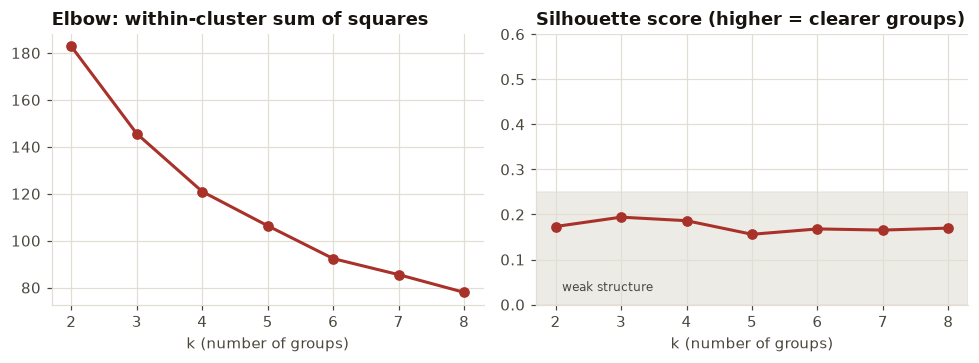

,within_1y_cc,within_1y_ep,within_1y_hmop,within_1y_mcop,within_1y_os,within_1y_stc,open_at_cutoff_2015_filings,districts
group 0,30%,30%,44%,14%,26%,88%,37%,"Chennai, Nagapattinam, Ramanathapuram, Salem, Theni, Tiruchirappalli, Tiruvarur, Vellore, Virudhunagar"
group 1,15%,35%,57%,20%,35%,60%,44%,"Cuddalore, Erode, Kanniyakumari, Karur, Puducherry, Sivagangai, Thanjavur, The Nilgiris, Tirunelveli"
group 2,17%,24%,50%,9%,22%,76%,49%,"Ariyalur, Coimbatore, Dharmapuri, Dindigul, Kancheepuram, Krishnagiri, Madurai, Namakkal, Perambalur, Pudukkottai, Thoothukudi, Tiruppur, Tiruvallur, Tiruvannamalai, Viluppuram"


Takeaway: 3 groups by silhouette score, but the best score is only 0.19: the groups (faster, middle, slower districts) are a handy summary, not a real discovery.


In [21]:
from courtcases.clusters import choose_and_fit

profile_types = ["stc", "os", "cc", "mcop", "ep", "hmop"]
el["district"] = el["dist_code"].map(district_names)
profile = el[el["type"].isin(profile_types)].pivot_table(index="district", columns="type", values="within_1y", aggfunc="mean")
profile.columns = [f"within_1y_{c}" for c in profile.columns]
profile["open_at_cutoff_2015_filings"] = lab[lab["filing_year"] == 2015].assign(
    district=lambda d: d["dist_code"].map(district_names)).groupby("district")["ended"].apply(lambda s: 1 - s.mean())
clusters = choose_and_fit(profile)
check("best silhouette score", max(clusters.silhouette.values()), max(tn["district_clusters"]["silhouette"].values()))
print(f"chosen k = {clusters.k}; districts whose missing measure was filled with the median: {clusters.imputed}")

ks = sorted(clusters.silhouette)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
axes[0].plot(ks, [clusters.inertia[k] for k in ks], marker="o", color=ps.SERIES[0])
axes[0].set_title("Elbow: within-cluster sum of squares")
axes[1].plot(ks, [clusters.silhouette[k] for k in ks], marker="o", color=ps.SERIES[0])
axes[1].set_title("Silhouette score (higher = clearer groups)")
axes[1].set_ylim(0, 0.6)
axes[1].axhspan(0, 0.25, color=ps.GRID, alpha=0.6)
axes[1].text(2.1, 0.03, "weak structure", fontsize=8, color=ps.INK_2)
for ax in axes:
    ax.set_xlabel("k (number of groups)")
    ax.set_xticks(ks)
fig.tight_layout()
plt.show()

centres = clusters.centres.copy()
centres.index = [f"group {i}" for i in centres.index]
centres["districts"] = [", ".join(sorted(clusters.labels[clusters.labels == i].index)) for i in range(clusters.k)]
display(centres.style.format({c: "{:.0%}" for c in centres.columns if c != "districts"}))
print(f"Takeaway: {clusters.k} groups by silhouette score, but the best score is only "
      f"{max(clusters.silhouette.values()):.2f}: the groups (faster, middle, slower districts) are a handy "
      f"summary, not a real discovery.")

## B11 · How long cases stay pending (Kaplan–Meier curves)

**What.** For Tamil Nadu cases filed 2015–2018, the share of cases **still pending after a given
number of months**, using the Kaplan–Meier method (`survival.kaplan_meier`). Each day it looks at
the cases still being watched and how many of them ended that day, and keeps a running product:
S(t) = Π (1 − dᵢ/nᵢ), where dᵢ cases ended on day i out of nᵢ still being watched. A pending case is
watched until the data was collected and then simply stops being counted; a case sent to another
court stops at its transfer. We never guess what happened after we stopped seeing a case.

**What the method assumes.** It assumes that the reason we stopped watching a case has nothing to do
with how soon it would have ended. That is true for the collection date; for transfers it is only
roughly true.

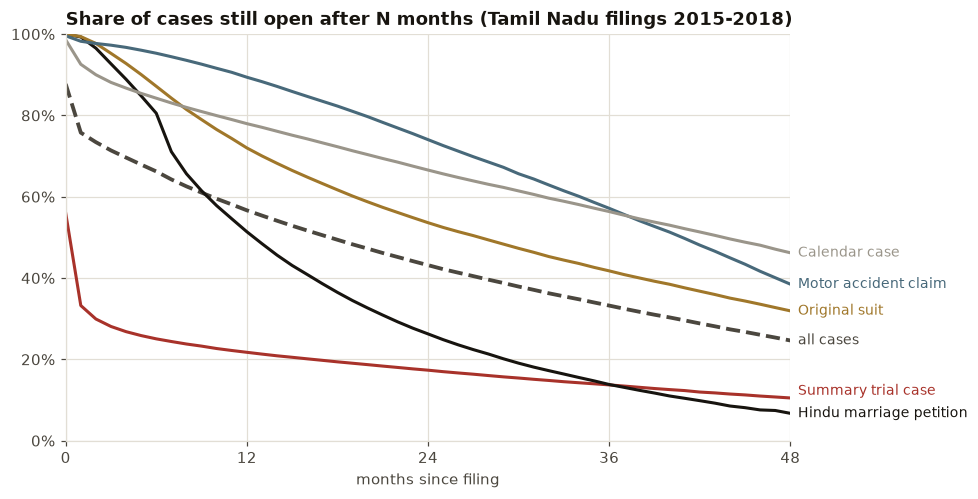

  [agrees] Kaplan-Meier median days, all cases: notebook 532.0000, report 532.0000
  [agrees] all cases still open after 12 months: notebook 0.5665, report 0.5665


,cases,median days,open after 12 months,open after 24 months,open after 48 months
all cases,"2,226,923",532,57%,43%,25%
Summary trial case,"582,598",2,22%,17%,10%
Hindu marriage petition,"62,525",379,51%,26%,7%
Original suit,"370,222",834,72%,54%,32%
Motor accident claim,"280,810","1,243",89%,74%,38%
Calendar case,"369,512","1,326",78%,67%,46%


Takeaway: half of all cases have ended after 532 days; 57% are still pending after a year and 25% after four years. Petty-offence cases end in days (typical 2); criminal cases before a magistrate take years (typical 1,326).


In [22]:
from courtcases.survival import still_open_at

recent = lab[(lab["unusable"] == "") & lab["filing_year"].between(2015, 2018)]
show = [("all cases", recent)] + [(t, recent[recent["type"] == t]) for t in ("stc", "hmop", "os", "mcop", "cc")]
months = np.arange(0, 49)   # 2015 filings were watched for about 48 months before the cutoff
fig, ax = plt.subplots(figsize=(8.5, 4.8))
ends = []
table_rows = {}
for i, (name, part) in enumerate(show):
    km = kaplan_meier(part["observed_days"], part["ended"])
    vals = still_open_at(km, months * 30.44)
    label = "all cases" if name == "all cases" else CASE_TYPES[name].split(" (")[0]
    color = ps.INK_2 if name == "all cases" else ps.SERIES[i - 1]
    ax.plot(months, vals, color=color, lw=2.5 if name == "all cases" else 2, ls="--" if name == "all cases" else "-")
    ends.append([float(vals[-1]), label, color])
    table_rows[label] = {"cases": len(part), "median days": median_days(km),
                         **{f"open after {m} months": vals[m] for m in (12, 24, 48)}}
ends.sort()
for j in range(1, len(ends)):   # push the end labels apart so none overlap
    ends[j][0] = max(ends[j][0], ends[j - 1][0] + 0.055)
for y, text, color in ends:
    ax.annotate(text, (48, y), xytext=(5, 0), textcoords="offset points", va="center", fontsize=9, color=color)
ax.set_xlim(0, 48)
ax.set_ylim(0, 1)
ax.set_xticks([0, 12, 24, 36, 48])
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlabel("months since filing")
ax.set_title("Share of cases still open after N months (Tamil Nadu filings 2015-2018)")
plt.show()
curves = pd.DataFrame(table_rows).T
check("Kaplan-Meier median days, all cases", curves.loc["all cases", "median days"], tn["still_open_curves"]["all cases"]["median_days"], tol=0.5)
check("all cases still open after 12 months", curves.loc["all cases", "open after 12 months"], tn["still_open_curves"]["all cases"]["still_open"]["12"])
display(curves.style.format({"cases": "{:,.0f}", "median days": "{:,.0f}", "open after 12 months": "{:.0%}",
                             "open after 24 months": "{:.0%}", "open after 48 months": "{:.0%}"}))
print(f"Takeaway: half of all cases have ended after {curves.loc['all cases', 'median days']:,.0f} days; "
      f"{curves.loc['all cases', 'open after 12 months']:.0%} are still pending after a year and "
      f"{curves.loc['all cases', 'open after 48 months']:.0%} after four years. Petty-offence cases end in days "
      f"(typical {curves.loc['Summary trial case', 'median days']:.0f}); criminal cases before a magistrate take years "
      f"(typical {curves.loc['Calendar case', 'median days']:,.0f}).")

## B12 · Limitations

**What.** `scripts/experiments.py` tested the chosen model in four ways; the results are read here.

1. **Inside one type of case it is weak.** Within a single case type the AUC is only 0.49–0.62 for
   rent, domestic violence, maintenance, execution, marriage and civil-suit cases. The model knows
   which *types* of case are quick, but between two cases of the same type it can barely tell.
2. **Things change over time.** Courts got faster every year, so a model that learned from 2015–16
   expects slightly too few quick cases in 2017. Giving 2016 more weight barely helps.
3. **Other time limits.** The same method for "within 6 months" and "within 2 years" also beats the
   case-type rule, so the result is not special to one year.
4. **Collection-date rule.** A stricter and a looser version of the collection-date rule give the
   same 2017 results.

Also: only Tamil Nadu; cases filed 2015–2017 and collected in early 2019, so courts may have changed
since; the "how busy is the court" inputs on the website are the values at the end of the data; and
it is a summary of past cases, not a prediction for any real case and not legal advice.

In [23]:
weak = pd.DataFrame(E["weak_spots"]["case_type"])
weak["kind of case"] = weak["case_type"].map(lambda t: CASE_TYPES.get(t, t).split(" (")[0])
print("1. AUC within a single kind of case (2017, kinds with 2,000+ cases; weakest first):")
display(weak.set_index("kind of case")[["auc", "n", "mean_predicted", "observed"]].head(8)
        .rename(columns={"auc": "AUC within the kind", "n": "cases", "mean_predicted": "mean prediction", "observed": "observed share"})
        .style.format({"AUC within the kind": "{:.2f}", "cases": "{:,}", "mean prediction": "{:.0%}", "observed share": "{:.0%}"}))

drift = pd.DataFrame(E["drift"]).T[["auc", "brier", "mean_predicted", "observed"]].astype(float)
print("2. Drift (test: 2017):")
display(drift.rename(columns={"auc": "AUC", "brier": "Brier", "mean_predicted": "mean prediction", "observed": "observed share"})
        .style.format({"AUC": "{:.3f}", "Brier": "{:.3f}", "mean prediction": "{:.1%}", "observed share": "{:.1%}"}))

horizons = pd.DataFrame({k: {"model AUC": v["model"]["auc"], "per-type baseline AUC": v["baseline: rate per case type"]["auc"],
                             "train years": str(v["train"]), "test year": v["test"]} for k, v in E["horizons"].items()}).T
print("3. Other horizons:")
display(horizons)

rule = {k: v["model_2017"]["auc"] for k, v in E["cutoff_rule"].items()}
print(f"4. Cutoff rule: 2017 AUC with the looser rule {rule['share 0.25']:.4f}, with the stricter rule {rule['share 0.5']:.4f}")

served_drift = drift.loc["train 2015-16 (served)"]
print(f"\nTakeaway: within one type of case the AUC drops to {weak['auc'].min():.2f}-{weak['auc'].iloc[5]:.2f} for the six "
      f"weakest types; the model predicts {served_drift['mean_predicted']:.1%} for 2017 when {served_drift['observed']:.1%} "
      f"happened (courts kept getting faster). It is a summary of 2015-2017 Tamil Nadu cases, not a forecast "
      f"for any real case.")

1. AUC within a single kind of case (2017, kinds with 2,000+ cases; weakest first):


,AUC within the kind,cases,mean prediction,observed share
kind of case,,,,
Rent control petition,0.49,"3,216",29%,33%
Domestic violence case,0.50,"3,309",24%,21%
Maintenance case,0.56,"4,898",30%,38%
Preliminary register case,0.56,"3,812",30%,27%
Execution petition,0.58,"35,950",28%,32%
Hindu marriage petition,0.58,"15,768",46%,51%
Sessions case,0.59,"9,220",29%,29%
Original suit,0.62,"86,542",27%,31%


2. Drift (test: 2017):


,AUC,Brier,mean prediction,observed share
train 2015-16 (served),0.873,0.138,47.3%,49.5%
train 2016 only,0.873,0.138,48.2%,49.5%
"train 2015-16, 2016 weighted 3x",0.874,0.137,47.7%,49.5%


3. Other horizons:


,model AUC,per-type baseline AUC,train years,test year
180 days,0.917159,0.872191,"[2015, 2016]",2017
365 days,0.873491,0.82753,"[2015, 2016]",2017
730 days,0.826065,0.771142,"[2014, 2015]",2016


4. Cutoff rule: 2017 AUC with the looser rule 0.8735, with the stricter rule 0.8735

Takeaway: within one type of case the AUC drops to 0.49-0.58 for the six weakest types; the model predicts 47.3% for 2017 when 49.5% happened (courts kept getting faster). It is a summary of 2015-2017 Tamil Nadu cases, not a forecast for any real case.


## B13 · Trying real cases on the saved model

**What.** Two real 2017 test cases (never used for training) go through the saved model exactly as on
the website: the facts known on the filing day go in, a chance comes out, and we compare it with what
really happened. The website's server (`game/backend/auditor/court_model/`) loads this same
`model.joblib`, and one of its tests checks that it gives exactly the same answer as this notebook.

In [24]:
from courtcases.glossary import section_name

picks = []
for want in [("Chennai", "Negotiable Instruments Act s.138"), ("Madurai", "Motor Vehicles Act s.166")]:
    rows_ = test[(test["district"] == want[0]) & (test["law_section"] == want[1])]
    picks.append(rows_.sample(1, random_state=7).index[0])
shown = test.loc[picks, CATS + NUMS].copy()
prob = served.predict_proba(shown)[:, 1]
outcome = lab.loc[picks]
summary = shown.T.copy()
summary.columns = [f"case {i + 1}" for i in range(len(picks))]
summary.loc["--- what the case is about"] = [f"{section_name(r['law'], r['law_section'].split(' s.')[1])}"
                                               if " s." in r["law_section"] else r["law"] for _, r in shown.iterrows()]
summary.loc["--- model: probability of finishing within a year"] = [f"{p:.0%}" for p in prob]
summary.loc["--- what happened"] = [
    f"{'finished' if o['ended'] else 'still open'} after {int(o['observed_days']):,} days "
    f"({'within a year' if o['within_1y'] == 1 else 'not within a year'})" for _, o in outcome.iterrows()]
display(summary)

print(f"Takeaway: the model gave the cheque-bounce case {prob[0]:.0%} and the accident claim {prob[1]:.0%}; "
      f"in reality they took {int(outcome.iloc[0]['observed_days']):,} and {int(outcome.iloc[1]['observed_days']):,} days. "
      f"The website otlr.vercel.app/model uses the same model file and the same inputs.")

,case 1,case 2
district,Chennai,Madurai
court_level,Magistrate court,Motor accident claims tribunal
case_type,cc,mcop
filing_month,8,10
law,Negotiable Instruments Act,Motor Vehicles Act
law_section,Negotiable Instruments Act s.138,Motor Vehicles Act s.166
ipc_bailable,not an IPC case,not an IPC case
criminal,civil,civil
log_prev_year_filings,9.713477,8.150756
log_pending_at_filing,10.63164,6.828712


Takeaway: the model gave the cheque-bounce case 5% and the accident claim 3%; in reality they took 530 and 464 days. The website otlr.vercel.app/model uses the same model file and the same inputs.


## B14 · Extra analysis: how disputes end, settled or dismissed

**What.** A second question on the same cleaned data: within two years of filing, does a real dispute
end in a **settlement** (compromise, Lok Adalat, withdrawn or compounded) or get **dismissed** without
a decision? `scripts/analyse_settlement.py` learns from 2015 cases and is tested on 2016 cases, using
logistic regression on case type, district, type of court and law.

**Why it is here.** A legal-aid office would like to know which new cases are worth sending to
mediation.

**A fair test.** Every case is watched for the full two years, including the ones still going. If we
only scored cases that had already ended, the results would look much better, but on the filing day
nobody knows which cases those will be. Each model is compared with simple look-up tables, so the
model has to earn its place.


In [25]:
S = json.loads((REPORTS / "settlement.json").read_text())   # scripts/analyse_settlement.py
from courtcases.difficulty import EASY_TYPES
from courtcases.settlement import ended_as

disputes = lab[(lab["filing_year"] == S["test_year"]) & ~lab["type"].isin(EASY_TYPES)]
settled_here = ended_as(disputes, "settled", S["horizon_days"]).mean()
check("share of 2016 disputes settled within two years", settled_here, S["targets"]["settled"]["base_rate"])

rows = {}
for target, t in S["targets"].items():
    rows[(target, "always guessing")] = {"AUC": 0.5, "accuracy": t["always_guessing_accuracy"]}
    for name, key_ in [("lookup: case type", "lookup_case_type"), ("lookup: case type x law", "lookup_case_type_and_law"), ("logistic regression", "logistic_regression")]:
        rows[(target, name)] = {"AUC": t[key_]["auc"], "accuracy": t[key_]["accuracy"]}
display(pd.DataFrame(rows).T.style.format({"AUC": "{:.3f}", "accuracy": "{:.1%}"}))

display(pd.DataFrame(S["by_case_type"])[["name", "cases", "dismissed", "settled"]].set_index("name")
        .style.format({"cases": "{:,}", "dismissed": "{:.1%}", "settled": "{:.1%}"}))

d, s, trap = S["targets"]["dismissed"], S["targets"]["settled"], S["finished_cases_only_dismissed"]
cheque = next(x for x in S["criminal_calendar_by_law"] if x["law"] == "Negotiable Instruments Act")
ipc = next(x for x in S["criminal_calendar_by_law"] if x["law"] == "Indian Penal Code")
print(f"Scoring finished cases only would have claimed {trap['accuracy']:.1%} against {trap['always_guessing_accuracy']:.1%}.")
print(f"Takeaway: dismissal depends mostly on the type of case: {d['logistic_regression']['accuracy']:.1%} against {d['always_guessing_accuracy']:.1%} for always guessing. "
      f"Settlement is rare ({s['base_rate']:.1%} within two years) but the model can rank it (AUC {s['logistic_regression']['auc']:.2f}): "
      f"in magistrate cases, {cheque['settled']:.1%} of cheque-bounce cases settle against {ipc['settled']:.1%} of Indian Penal Code cases.")


  [agrees] share of 2016 disputes settled within two years: notebook 0.0341, report 0.0341


,cases,dismissed,settled
name,,,
Original suit (civil),"162,085",13.8%,4.4%
Calendar case (criminal trial before a magistrate),"151,136",2.9%,2.4%
Motor accident claim,"86,845",12.1%,2.9%
Execution petition (enforcing a decree),"62,163",51.1%,2.3%
Hindu marriage petition,"23,908",24.3%,1.4%
Original petition,"20,246",24.6%,3.0%
Sessions case (serious criminal trial),"16,128",6.3%,0.3%
Appeal suit (civil appeal),"11,767",17.1%,0.8%


Scoring finished cases only would have claimed 74.5% against 62.7%.
Takeaway: dismissal depends mostly on the type of case: 85.0% against 83.7% for always guessing. Settlement is rare (3.4% within two years) but the model can rank it (AUC 0.75): in magistrate cases, 9.9% of cheque-bounce cases settle against 0.7% of Indian Penal Code cases.


## Summary

**Part A, the data.** 81 million raw court records, read as text. We cleaned 29,857 spellings of law
names, hand-typed court names and sections, impossible dates and special codes, using small tested
rules that count every change. Two facts shaped everything: the data was collected in
January–February 2019 (found from the sudden drop in monthly decisions, for each district), and the
early years are missing their quick cases, so we only model cases filed 2015–2017. "Finished within
a year" is only given to cases that had a full year, which fixed a mistake that made 2018 look more
than 90% "quick".

**Part B, the model.** Twelve facts known on the filing day, nothing from the future, no gender.
Learn from 2015, choose on 2016, test once on 2017. Three kinds of model against three simple rules:
the law inputs matter far more than which model we use. Our logistic regression is right about 8
times in 10 on 549,273 new cases (AUC 0.873, Brier 0.138, against 0.844 and 0.163 for a look-up
table), and its chances match reality. But most of that comes from easy cases: on real disputes it is
right 74.3% of the time, against 72.0% for always guessing the most common answer (B7), and models
trained only on disputes do no better. The filing day tells us the type of case and not much more;
most of a dispute's time comes after its first hearing (A9). Inside one type of case the model is
weak, and courts got faster each year. The regression on days and the district groups are side
analyses, and we report them as weak. How a dispute ends (B14) depends mostly on the type of case;
settlement is rare but can be ranked, and cheque-bounce cases settle far more often than Indian Penal
Code cases.

The code below lists every check in this notebook where a number calculated here is compared with
the same number in the reports.

In [26]:
agree = sum(ok for _, ok in CHECKS)
print(f"{agree} of {len(CHECKS)} numbers computed in this notebook agree with reports/*.json")
for what, ok in CHECKS:
    if not ok:
        print("  DISAGREES:", what)

33 of 33 numbers computed in this notebook agree with reports/*.json
